In [ ]:
# a = 42, b = 42, это две ссылки на один и тот же объект в памяти, а не два разных значения

# раньше инты были ограниченные в питоне, но сейчас все еще есть ограничения, но не бесконечное, int 4 байта, - 2^31 ... (погуглить и дописать)

# питон может даже больше чем 64 бита использовать при обычной арифметике, если архитектура пк позволяет, и уже потом использовать длинную арифметику (операции в столб и каждый разряд большое число)

# a = 42. - double (не float ,возможно в питоне нет float), 8 байт - (1 бит на знак, эксп, мант), (too complement почитать про это), в питоне все числа со знаком кроме unsigned (unsigned long long name = -1; (max число в плюсах)) Также есть статическая точка и плавающая, тоже об этом почитать стоит

# Кодировки для символов есть разные, utf8-16 (обычно utf-8 кроме винды используется везде), строки в питоне не изменяемые, для хеширования строк как ключей чтобы посчитать хеш для строки один раз и потом хэш не поменяется, строку можно просто перезаписать, но не изменить

# -13 % 5 = 2 остаток будет, как в плюсах (почитать почему)

# 10. ** 3 = 1000. - сохранит исходный тип

# 3 ^ 2 - 1 (xor операция)

# 2 | 1 - побитовое или= 3

# 2 & 1= 0 # сдвиги 1 << 5, 1 >> 5 (поделить на 2 в степени ...)

# строки можно умножать, складывать, срезать '1234234'[0] ... [-1] [0:5:2] переворот [::-1]

# a = '123456789'[-1: len(a) - 1: -1] перевернет строку



`Питон` - динамически типизированный язык


*Динамически типизированный* - значит тип определяется во время работы программы, а не при ее написании или комипиляции

### Принято делить ЯП по несокльким группам


#### По способу выполнения кода:

- *Компилируемые* - специальная программа-компилятор берет весь код и переводит его в один исполняемый файл, то есть, допустим в файл `.exe` `c++, rust, go` Долгий запуск, бытсрая работа

- *Интерпретируемые* - специальная программа-интерпритатор читает код строку за стркоой прямо во время запуска и сразу выполняет его `python, php`. Быстрый запуск, медленная работа

- *Гибридные* - код-сначала компилируется в промежуточный формат, байт-код, а специальная виртуальная машина компилирует его в машинный код (JIT-компиляция). Ну и это компромис между скоростью запуска и скоростью работы программы


#### По типизации:

- *Статическая* - тип сущности известен на момент написания кода / компиляии, его надо явно задавать в коде и нельзя менять
- *Динамическая* - тип сущности становится известен во время запуска программы, переменная может менять тип


*Плюс к этому:*
- Строгая (Python) - нельзя смещивать разные типы данных (число сложить со строкой)
- Слабая (JS) - можно смешивать разные типы, язык сам пытается привести типы

#### По уровню:

- Низкоуровневые
- Высокоуровневые

#### По парадигме

- *Императивные* (C, Pascal) - код пишется как последовательность инструкций
- *ООП* - программа строится вокруг объектов
- *ФП* - программа предствляет собой цепочку математических функций, где переменная меняет свое состояния (Haskel, Scala, Elixir)

В питоне все является ссылками, то есть если в памяти есть число 42, то переменные a и b на самом деле ссылаются на одно и тоже значение

In [ ]:
a = 42, b = 42

# Целочисленная арифметика

Сейчас в питоне нет ограничений на длину числа `int`, оно ограничивается только размером памяти компьютера, это в Python3 появилось

Типа `long` также нет, он объединен с `Int` типом

Питон числа разбивает на блоки по 30 бит, то есть по 30 символов, не по 32 потому что нужно избежать переполнения при умножении

- Например, число 2^100 хранится как массив из 4 элементов по 30 бит каждый
- Его общая память составляет 40 байт, потому что 24 байта на заголовок + 4*4 байта ~ 40 байт

В СPython реализация интового числа представлена в виде объекта, который содержит заголовок, состоящий из определенных служебных полей, которые занимают определенное количество памяти, например:

#### Упрощенная структура из исходников Cpython

```python
type struct {
    PyObject_VAR_HEAD, - заголовок, примерное 24 или 28 байт
    digit ob_digit[1]; - массив цифр по 30 бит
} PyLongObject;

 ```

Размер заголовка зависит от того, какая архитектура процессора, 32 или 64, обычно на 64 битных по 28 для малых чисел используется


Любая сущность в питоне потсроена на основе `PyObject` из `C` и которая тащит за собой в памяти как минимум два поля в заголовке, а именно:

- `ob_refcnt` счетчик ссылок, если на один объект в памяти (пусть будет число 42) есть несколько ссылок, то память занята, но если вдруг это число = 0, то память освобождается 


```python
a = 42          # refcnt = 1
b = a           # refcnt = 2  
del a 
``` 


- `ob_type` указатель на тип
Благодаря этому питон динамически типизированный язык и во время выполнения он знает о типе переменнной


Для чисел добавляется еще всегда поле `ob_size`, далее из из документации:

*Он есть у объектов, которые имеют некоторое представление о длине*

Рассмотрим то, как число 0 представлено внутри памяти питона:

Памяти выделяется 32 бита, 30 под число и 2 под запас

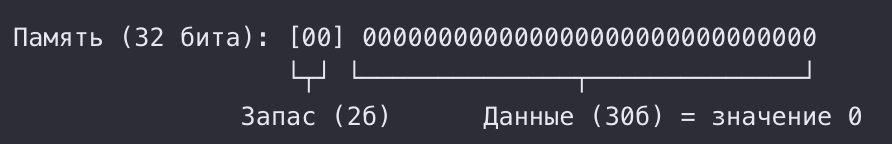

Так как само 30-битное число = 0, то `ob_size = 0`, то есть само число ничего не весит, но в объекте уже выделено 4 байта под само число и 24 под заголовки, то есть 28 байт в сумме

Теперь рассмотрим то, как число 1 представлено в памяти питона:

Памяти выделяется 32, 30 под число, 2 про запас

Но, теперь `ob_size` = 1, так как в 30 разрядах появилась единица

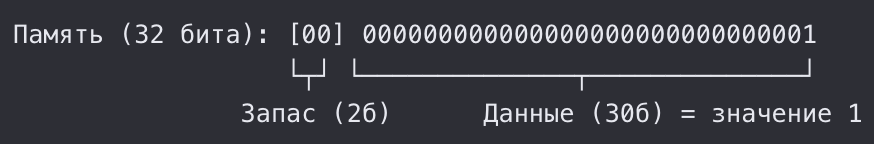

Так как само 30-битное число = 1, то `ob_size = 1`, в объекте уже выделено 4 байта под само число и 24 под заголовки, то есть 28 байт в сумме

Собственно, все числа до 2^30 - 1 будут весить по 28 байт

Для числа 2^30, которое не помещается в 28 байт, мы просто пристаиваем еще одну коробку в 4 байта (то есть 32 бита) и размерность увеличивается до 2^60 - 1

Почему под блок 4 байта? Потому что в питоне договорняк, что под разряд числа мы выделяем 32 бита, (30 на число, 2 на запас над операциями), в 32 бита влезает 4 байта (1 байт = 8 бит, их как раз помещается 4)

Подведем итоги:
- 24 байта под заголовки (при 64 разрядной архитектуре)
- 4 байта под 2^30 - 1 чисел (30 под число, 2 на длинную арифметику)
- Потом мы при переполнении, начиная с 2^30 добавялем по 4 байта под число и размер числа увеличивается до 32 байтов

# Отрицательные целые числа

В питоне то, что число отрицательное, можно узнать по все тому же полю `ob_size` у объекта. Если оно отрицательное, значит уже и само число отрицательное. Ну а дальше там применяется классическая процедура представления отрицательных чисел в памяти ПК

Получше разобрать эту тему

# Вещественные числа

# Вещественные отрицательные числа

## Операции над вещественными числами (главное вычитание)

# Строки

In [2]:
' abc '.join('123')

'1 abc 2 abc 3'

In [3]:
'123'.split('3')

['12', '']

In [ ]:
a = '12 345 6 /t7 89' # в каких то версиях может пропасть символ табуляции на сплите по пустой строке ,но не в 3 10
a.split()


['12', '345', '6', '/t7', '89']

In [8]:
f'{10 + 30}'

'40'

In [9]:
f'{10 + 20:05d}'

'00030'

In [11]:
f'{10 + 20:05d}, {10 + 20=}'

'00030, 10 + 20=30'

In [12]:
r'\t\n\r'

'\\t\\n\\r'

In [13]:
print(r'\t\n\r123')

\t\n\r123


In [14]:
'%d + %d = %d' % (10, 20, 30)

'10 + 20 = 30'

In [15]:
'{} + {} = {}'.format(10, 20, 30)

'10 + 20 = 30'

In [ ]:
f = '{} + {} = {}'
f = '{0} + {2} = {1} ({2})'
f.format(10, 20, 30)

'10 + 30 = 20 (30)'

In [49]:
# списки - изменяемая послед элементов, в нем тип данных наз-ся ссылка
a = [1, 2, 3, 4, 5, 6]
a.append(10)

In [21]:
a.extend(a)
a

[1, 2, 3, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10]

In [ ]:
# a[start:stop:step]
a[0:2]

[1, 2]

In [75]:

a[1:3]  = [5, 6, 7, 8]
a

NameError: name 'a' is not defined

In [25]:
a + a

[1,
 5,
 6,
 7,
 8,
 7,
 8,
 4,
 5,
 6,
 10,
 1,
 2,
 3,
 4,
 5,
 6,
 10,
 1,
 5,
 6,
 7,
 8,
 7,
 8,
 4,
 5,
 6,
 10,
 1,
 2,
 3,
 4,
 5,
 6,
 10]

In [50]:
a * 3

[1, 2, 3, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10]

In [ ]:
a.append(a)
a
# ссылку на список положили в список

[1, 5, 6, 7, 8, 7, 8, 4, 5, 6, 10, 1, 2, 3, 4, 5, 6, 10, [...], [...]]

In [ ]:
a = [[1, 2]] * 3 # поменяли объект по одной и той же ссылке, список буквально явялется вектором как в плюсах почитать
a[0].append(3)
a

[[1, 2, 3], [1, 2, 3], [1, 2, 3]]

In [ ]:
# кортеж - нельзя менять
a = (1, 2, 3, 4)
a[1] = 2

TypeError: 'tuple' object does not support item assignment

In [32]:
(1)

1

In [33]:
(1,)

(1,)

In [ ]:
# неизменяемые потому что хеширование и не надо ключи пересоздавать

In [ ]:
# множества, нельзя обратится по индексу и тд
a = {1, 2, 3, 4, 5}

In [ ]:
a = {'a' : 1, 'b' : 2, 3: 4} # ассоциированный массив
a

{'a': 1, 'b': 2, 3: 4}

In [36]:
a['b']

2

In [37]:
a[(1, 2)] = 5

In [38]:
a[[1, 2]] = 5 # нельзя

TypeError: unhashable type: 'list'

In [39]:
a

{'a': 1, 'b': 2, 3: 4, (1, 2): 5}

In [ ]:
# new_list = [выражение for элемент in итерируемый_объект] list comprehention



In [ ]:
# frozen set, это просто класс в питоне, ничего такого, это обычный сет но который нельзя изменять

# [] vs {} - просто более удобная абстракция, 
# то есть если мы знаем заранее все элементы, то лучше использовать [], иначе лучше использовать {} если мы не знаем

In [ ]:
a = None
# значит ничего, но потом появится, нужно для того чтобы выделить память, потому что в питоне может ссылаться на чтото, также None всегда один объект на весь исполняемый файл

type(None)() is None

True

In [ ]:
# Nan - не число, нужно для того чтобы покать, что результат не может быть числом, не существует такого числа
# все операции с nan это nan
# null нет в питоне из-за его особенностей, так как ссылка всегда должна ссылаться на какой то объект в питоне, то есть для этого есть None

In [44]:
i = 0
while i < 10:
    print(i)

    i += 1

0
1
2
3
4
5
6
7
8
9


In [ ]:
for i in range(10):
    print(10)

range(10)

10
10
10
10
10
10
10
10
10
10


range(0, 10)

In [ ]:
# for i in # любой объект по которому модно итерироваться

In [ ]:
for i in range(1, 10):
    if i % 2 == 0:
        print(i)

    if i % 5 == 0:
        break
# ексли ни разу не выполнился цикл
else:
    print('fo')

2
4


In [ ]:
print('fdsfsd', end="")

In [1]:
print('Fizz' if a % 3 == 0 else 'Buzz' if a % 5 == 0 else 'OHNO')

NameError: name 'a' is not defined

In [2]:
print('Красный\nОранжевый\nЖелтый\nЗеленый\nГолубой\nСиний\nФиолетовый')

Красный
Оранжевый
Желтый
Зеленый
Голубой
Синий
Фиолетовый


In [16]:
params = (int(input()) for _ in range(3))

x, y, t = params

print((t * y) - x * (t // 10))


5


In [ ]:
params = (int(input()) for _ in range(2))
n, m = params
print(n / m)

1.5


In [36]:
number = int(input())
print(('Fizz' if number % 3 == 0 else '') + ('Buzz' if number % 5 == 0 else ''))

FizzBuzz


In [47]:
a = int(input())
b = int(input())

if a >= b or b == a:
    total = 0
else:   
    total = b + (b % 4)

print(total)

16


In [69]:
a, b = map(int, open('input.txt').read().split())

list_sum = a + b - 1
if list_sum % 4 == 0:
    total = list_sum
else:
    total = 0

f = open('output.txt', 'w')
print(total)
f.write(str(total))
f.close()

0


In [154]:
f = open('input.txt')
data = []

data = [[float(i) for i in line.split()] for line in f]

D, T = data[0]
u1, u2 = data[1]
w1, w2 = data[2]

def get_thinking_s(D: float, T: float, u: float, w: float) -> float:
    print(f'params - {D, T, u, w}')
    deniminator = (u - w)

    if deniminator > 0:
        return
    
    return  ((D - w * T) / deniminator) * u

max_s = 0

def compare_best_s_with_legal_s(legal_s: float, total_s: float) -> bool:
    print(f'compare - {True if legal_s <= total_s else False}')
    return True if legal_s <= total_s and total_s > 0 else False

for i_el in data[1]:
    for j_el in data[2]:
        thinking_time = get_thinking_s(D, T, i_el, j_el)
        print(f'thinking_time = {thinking_time}')

        if compare_best_s_with_legal_s(thinking_time, D):
            max_s = max(max_s, thinking_time)

        print(f'max_s = {max_s}')

        print('\n')


f = open('output.txt', 'w')
round_max = round(total, 3)
print(round_max)
f.write(str(round(total, 3)))

print(max_s)

params - (15.0, 3.0, 1.0, 4.25)
thinking_time = -0.6923076923076923
compare - True
max_s = 0


params - (15.0, 3.0, 1.0, 6.1)
thinking_time = 0.6470588235294112
compare - True
max_s = 0.6470588235294112


params - (15.0, 3.0, 2.5, 4.25)
thinking_time = -3.2142857142857144
compare - True
max_s = 0.6470588235294112


params - (15.0, 3.0, 2.5, 6.1)
thinking_time = 2.2916666666666647
compare - True
max_s = 2.2916666666666647


7.5
2.2916666666666647


In [ ]:
f = open('input.txt')
data = []

data = [[float(i) for i in line.split()] for line in f]

D, T = data[0]
u1, u2 = data[1]
w1, w2 = data[2]

def get_thinking_s(D: float, T: float, u: float, w: float) -> float:
    deniminator = (u - w)

    if deniminator == 0:
        return 0.0
    
    return  ((D - w * T) / deniminator) * u

max_s = 0

def compare_best_s_with_legal_s(legal_s: float, total_s: float) -> bool:
    return True if legal_s <= total_s and total_s > 0 else False

for i_el in data[1]:
    for j_el in data[2]:
        thinking_time = get_thinking_s(D, T, i_el, j_el)

        if compare_best_s_with_legal_s(thinking_time, D):
            max_s = max(max_s, thinking_time)


f = open('output.txt', 'w')
round_max = round(max_s, 3)
f.write(str(round_max))
f.close()

In [184]:
f = open('input.txt')
data = []

data = [[int(i) for i in line.split()] for line in f]

h_start, m_start = data[0]
h_way, m_way = data[1]

m_add = h_way * 60 + m_way

total_m = (h_start * 60 + m_start + m_add) % (24 * 60)

f = open('output.txt', 'w')
f.write((f'{str(total_m // 60)} {str(total_m % 60)}'))

f.close()

In [ ]:
word = input()

happy = ["Просто!", "Easy!", "Einfach!"]

if word in happy:
    print(':)')
else:
    print(':(')


:)


In [190]:
secondname = input()
name = input()
role = input()

print(f'{secondname}.{name}@{role}.dvfu.ru')

# [фамилия].[имя]@[роль].dvfu.ru


sdfdsf.ff@fdsf.dvfu.ru


In [193]:
secondname = input()
name = input()
print(f'Меня зовут {name}\n{secondname} {name}')

Меня зовут Бонд
Джеймс Бонд


In [79]:
f = open('input.txt')

a, b, t = map(int, open('input.txt').read().split())

P = 2 * a + 2 * b

intervals = [
    (0, a, 'S'),
    (a, a + b, 'E'),
    (a + b, (2 * a) + b, 'N'),
    ((2 * a) + b, P, 'W'),
]

# dirs = {
#     '0' : 'S',
#     f'{a}' : 'S',
#     f'{b}' : 'E',
#     f'{2 * a}' : 'N',
#     f'{2 * b}' : 'W'
# }

answ = ''

position = (t % P)

print(position)

for interval in intervals:
    x, y, direct = interval

    if x <= position < y:
        answ = direct
    else:
        answ

f = open('output.txt', 'w')
f.write(str(answ))
f.close()

0


In [112]:
sentece_type = {
    ',' : 'сложное',
    '?' : 'вопросительное',
    '!' : 'восклицательное',
}

sentence = input()

answer = ''

for types in sentece_type.keys():
    if types in sentence:
         if len(answer) > 0:
              answer += ' '

         answer += sentece_type[types]

answer = answer.replace('вопросительное восклицательное', 'вопросительно-восклицательное')


if len(answer) == 0:
     answer = 'повествовательное'
elif len(answer.replace('сложное', '')) == 0:
    answer = answer + ' повествовательное'

print(answer)

повествовательное


In [113]:

while True:
    line = input()

    if line == "Stop!":
        print('Ок')
        break

    print('Каша')

Каша
Каша
Каша
Ок


In [126]:
n = int(input())

exclamation = '!'
counter = 0

for i in range(n, -1, -1):
    if i == 0:
        print(f'Start{exclamation * counter}')
        break

    print(f'{i}{exclamation * counter}')
    counter += 1


5
4!
3!!
2!!!
1!!!!
Start!!!!!


In [13]:
valid = 'boletus edulis'
counter = 0

n = int(input())

for i in range(n):
    if input().lower() == valid:
        counter += 1

print(counter)

1


In [20]:
n = int(input())

for i in range(1, n + 1):
    for j in range(1, n + 1):
        print(f'{i} * {j} = {i * j}')


1 * 1 = 1
1 * 2 = 2
1 * 3 = 3
2 * 1 = 2
2 * 2 = 4
2 * 3 = 6
3 * 1 = 3
3 * 2 = 6
3 * 3 = 9


In [36]:
n = int(input())
data = []
for _ in range(n):
    data.append(input())

print(*data[::-1], sep='\n')

Bin
mog
g'thazag
cha


In [39]:
# Побитовые операции в питоне

# Побитовый вывод числа, 0b бинарный тип, -0b отрицательыне бинарные числа
bin(9)
bin(-9)

'-0b1001'

In [42]:
# логическое И (работает по таблице истинности)

1 & 1

1

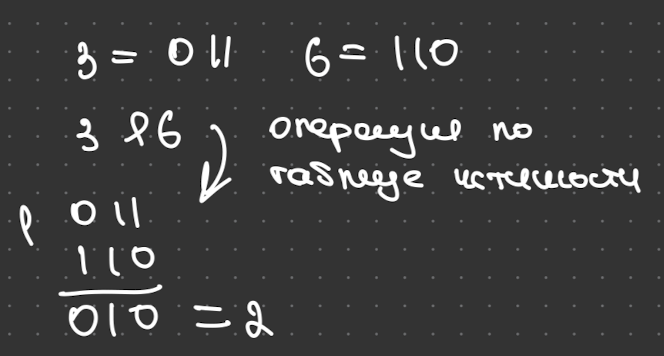

In [48]:
bin(3 & 6)

'0b10'

In [44]:
# логическое ИЛИ

0 | 0

0

In [50]:
3 | 6

7

In [52]:
# XOR ^
# 1 - если операнды разные
# 0 - если операнды одинаковые

1 ^ 1
199 ^ 198

1

In [2]:
# ~ not, работает по формуле -(x + 1)
bin(4)
bin(-4)

'-0b100'

In [ ]:
# Нужно учитывать, что положительные числа он преобразовывает в отрицательные
# Комп хранит числа байтами, то есть по 8 бит, и нам надо 
# Интересный факт CPython,  хранит числа инты по 30 бит, а не по 32, для того чтобы при сложении двух 30-разрядных чисел мы уложились в 64 бита, и не было переполнения, то есть можно было в СИ сохранить в long long


Операции вычитания как таковой на процессоре нет, есть операция сложения (x + y) и операция вычитания (x + (-y))

Пример: 5 - 3

5 + (-3)

Разберемся с 3, надо получить ее инверсию в битах
3 - 0000 0011
~3 - 1111 1100
~3 + 1 = 1111 1101 - это и есть -3

Теперь сложим
0000 0101 (5)
1111 1101 (-3)

1 0000 0010 - у нас получился 9 лишний бит, который процессор просто отбрасывает и получается число 2, что и является ответом на поставленную задачу

Такой подход помогает компу не уметь работать с вычитанием напрямую, а работать только через сложение, также это позволяет не возиться с -0 и +0

In [63]:
# побитовые сдвиги влево и вправо
1 << 1
# единица переместилась на 1 бит влево

# 0000 0001 << 1
# 0000 0010

2

In [64]:
1 << 2

# 0000 00010 << 1
# 0000 0100

4

In [65]:
2 << 3

16

In [66]:
3 << 2

12

In [67]:
# левый сдвиг можно ахарактеризировать через умножение или масштабирование информации и на самом деле это является x * 2^n, x << n

3 << 3
# 3 * 2^3 = 24

24

In [69]:
# правый сдвиг x // 2^n

10 >> 1

5

In [95]:
n, m = map(int, input().split())
data = map(int, input().split())

answer = data[m::] + data[0:m:]

print(*answer)

2 3 4 1


In [183]:
# n - N
# na - Na
# n_a - NA
# M_N - MN

# M - m
# Mn - mn
# MN - m_n
# MNN - m_n_n
# MyName = my_name

f = open('input.txt')
name = list(f.read())

answer = ''

if '_' in name or name[0].lower() == name[0]:
    name[0] = name[0].upper()

    for i in range(1, len(name)):
        if name[i - 1] == '_':
            name[i] = name[i].upper()

    answer = ''.join(name).replace('_', '')

else:
    for i in range(len(name) - 1, 0, -1):
        if 65 <= ord(name[i]) <= 90:
            name.insert(i, '_')

    answer = ''.join(name).lower()

f = open('output.txt', 'w')
f.write(answer)
f.close()

In [ ]:
# set - nums = {i for i in range(10)}

In [224]:
f = open('input.txt')

n = int(f.readline())

nums = {i : 0 for i in range(10)}

for i in range(n):
    el = int(f.readline())

    nums[el] += 1

f = open('output.txt', 'w')

temp = list(nums.values())[1::]
temp.append(list(nums.values())[0])

answ = ' '.join(map(str, temp))

f.write(answ)
f.close()

In [4]:
import sys

names = sys.stdin.read().split()

first_grop = []
second_group = []

for i in range(len(names)):
    if i % 2 == 0:
        second_group.append(names[i])
    else:
        first_grop.append(names[i])

print(*second_group, sep=', ')
print(*first_grop, sep=', ')

KeyboardInterrupt: 

In [156]:
# f = open('d.in')
# pfhrase = f.read()

pfhrase = input()

divider = {' . ', 
           ' .', 
           ' .', 
           '.' , 
           ', ', 
           ', ' 
           ' ,',
           ',',
           ' ! ', 
           '! ',
           ' !',
           '!',
           ' ? ',
           '? ',
           ' ?',
           '?',
           ' - ',
           ' -- ',
           ' ... '
           ' ...',
           }

for d in divider:
    pfhrase = pfhrase.replace(d, ' ')

pfhrase = pfhrase.split()

print(len(pfhrase))
# f = open('d.out', 'w')
# f.write(str(len(pfhrase)))
# f.close()


1


In [192]:
# group by

f = open('input.txt')
n = int(f.readline())

visited = {}

for i in range(n):
    group_name, student_name = f.readline().split('\t')
    group_name_cleared = group_name.replace('\n', '')

    student_name_cleared = student_name.replace('\n', '')


    if group_name_cleared not in visited:
        visited[group_name_cleared] = []

    visited[group_name_cleared].append(student_name_cleared)

f = open('output.txt', 'w')

for group in sorted(visited.keys()):
    f.write(group + '\n')
    visited[group].sort()
    f.write('\n'.join(visited[group]))
    f.write('\n')

f.close()

In [223]:
f = open('input.txt')
n = int(f.readline())

added = {}
fileNames = []

for i in range(n):
    file_name = f.readline().strip()
    
    if file_name.lower() not in added:
        added[file_name.lower()] = 1
        fileNames.append(file_name)

    else:
        new_name = file_name + str(added[file_name.lower()])
        suffix = added[file_name.lower()]
        new_name = file_name + str(suffix)
        
        fileNames.append(new_name)
        added[new_name.lower()] = 1

        added[file_name.lower()] += 1

f = open('output.txt', 'w')

for el in fileNames:
    f.write(str(el))
    f.write('\n')
    
f.close()

# 
f = open('input.txt')
n = int(f.readline())

added = {}
fileNames = []

for i in range(n):
    file_name = f.readline().strip()
    
    if file_name.lower() not in added:
        added[file_name.lower()] = 1
        fileNames.append(file_name)
    else:
        suffix = added[file_name.lower()]
        new_name = file_name + str(suffix)
        
        while new_name.lower() in added:
            suffix += 1
            new_name = file_name + str(suffix)
            
        added[file_name.lower()] = suffix + 1
        
        added[new_name.lower()] = 1
        fileNames.append(new_name)


f = open('output.txt', 'w')

f.write('\n'.join(fileNames)) 

f.close()

In [ ]:
import sys
strings = sys.stdin.read().split()

# f = open('input.txt')
# strings = f.read().splitlines()

last_seen = {}

prev_indices = []

for i in range(len(strings)):
    s = strings[i]
    
    if s in last_seen:
        index = last_seen[s]
    else:
        index = -1
    
    prev_indices.append(index)
    
    last_seen[s] = i

print(*prev_indices, sep='\n')


-1
-1
1
0
3


In [ ]:
import sys

n = int(input())

prices = list(map(int, sys.stdin.read().split()))

answer = 0
for price in prices:
    if answer >= 1000:
        break
    answer += price

print(answer)

2120


In [54]:
test_name = input()
test_treshold = float(input())

print(f"SELECT\n  id,\n  SUM(product_price) AS revenue_by_user\nFROM\n  dataset.data_table\nWHERE\n  ab_test = '{test_name}'\nGROUP BY\n  id\nHAVING\n  revenue_by_user < {test_treshold:.3f}")

SELECT
  id,
  SUM(product_price) AS revenue_by_user
FROM
  dataset.data_table
WHERE
  ab_test = 'ваыва'
GROUP BY
  id
HAVING
  revenue_by_user < 444.000


In [ ]:
# f = open('input.txt')
n, m, k = list(map(int, input().split()))

matrix = []

for i in range(n):
    matrix.append(list(map(int, input().split())))

direction = 1

if k < 0:
    direction = -1

k = abs(k) % 4

while k != 0:
    matrix_T = [[0] * len(matrix) for _ in range(len(matrix[0]))]


    if direction == 1:
        matrix = [list(i) for i in zip(*matrix[::-1])]
    else:
        matrix = [list(i) for i in zip(*matrix)][::-1]

    k -= 1

for m in matrix:
    print(*m)

3
7 4 1
8 5 2
9 6 3


In [229]:
arr = [1, 2, 3, 4]

zip(arr)

In [ ]:
# машина тьюринга

# n - возможный алфавит
# m - множество состояний
# k - длина массива текущих состояний

# Тройки - (символ, который нужно записать на ленту), (направление движения указателя), (состояние, в которое переходит машина)

from collections import defaultdict


f = open('input.txt')
n, m, k = map(int, f.readline().split())

# n, m, k = map(int, input().split())
commands = []


for i in range(n):
    line = f.readline().strip().split()
    state_commands = []
    
    for j in range(0, len(line), 3):
        command = line[j : j + 3]
        state_commands.append(command)
        
        if len(state_commands) == m:
            commands.append(state_commands)
            break
        
    # command = f.readline().split('  ')
    # command = input().split('  ')
    # for j in range(m):
    #     command[j] = command[j].replace('\n', '').split()

        # if j % 2 == 0:
        #      print(command[i][j])
            #  command[i][j] = int(command[i][j])

    # commands.append(command)

    

# for i in range(n):  
#     for j in range(m):
#         if j % 2 == 0:
#             commands[i][j] = int(commands[i][j])

# current_states = list(map(int, input().split()))

print(commands)
current_states = list(map(int, f.readline().split()))

alphabet = [i for i in range(n)]
states = [i for i in range(1, m + 1)]

directions = {'L' : -1, 'R' : 1, 'N' : 0}

current_state = 1
pointer = 0

tape = defaultdict(int) 

for i in range(len(current_states)):
    tape[i] = current_states[i]

# print(tape)
command = commands[tape[0]][0]
print(f'command {command}')
left = 0
right = 0

while current_state != m:
    value, action, state = command

    # print('состояния из команд', value, action, state)

    # print('меняем сотояние в ленте')
    tape[pointer] = (value)
    # print(f'текущая лента {tape}')

    pointer += directions[action]

    
    left = min(left, pointer)
    right = max(right, pointer)
    # print(f'текущий указатель {pointer}')
    
    current_state = int(state)

    # if current_state == m - 1:
    #     break
    # print(f'текущее состояние  {current_state}')

    # print(f'pointer {tape[pointer]}')
    command = commands[int(tape[pointer])][current_state - 1] 
    # print(command)


# print(left)
# print(right)

# print(tape)
print(*[tape[i] for i in range(left, right + 1)])

[[['0', 'N', '12'], ['0', 'R', '1'], ['3', 'L', '3'], ['0', 'L', '3'], ['3', 'R', '5'], ['0', 'R', '5'], ['0', 'R', '6'], ['0', 'R', '7'], ['0', 'R', '8'], ['0', 'N', '12'], ['0', 'R', '10'], ['0', 'L', '11']], [['1', 'N', '12'], ['1', 'R', '1'], ['1', 'N', '12'], ['1', 'L', '3'], ['3', 'R', '6'], ['1', 'R', '5'], ['1', 'R', '6'], ['1', 'R', '7'], ['1', 'R', '8'], ['1', 'N', '12'], ['1', 'R', '10'], ['1', 'L', '11']], [['2', 'R', '1'], ['2', 'R', '2'], ['2', 'N', '12'], ['2', 'L', '4'], ['2', 'R', '9'], ['2', 'R', '7'], ['2', 'R', '8'], ['2', 'N', '12'], ['2', 'N', '12'], ['2', 'R', '10'], ['2', 'N', '12'], ['2', 'N', '12']], [['3', 'N', '12'], ['3', 'N', '12'], ['3', 'N', '12'], ['3', 'N', '12'], ['3', 'L', '4'], ['3', 'R', '5'], ['3', 'R', '6'], ['0', 'R', '2'], ['1', 'R', '2'], ['2', 'R', '9'], ['2', 'L', '11'], ['3', 'N', '12']]]
command ['2', 'R', '1']
2 1


In [67]:
# машина тьюринга

# n - возможный алфавит
# m - множество состояний
# k - длина массива текущих состояний

# Тройки - (символ, который нужно записать на ленту), (направление движения указателя), (состояние, в которое переходит машина)

from collections import defaultdict


f = open('input.txt')
n, m, k = map(int, f.readline().split())

# n, m, k = map(int, input().split())
commands = []
for i in range(n):
    
    command = f.readline().split('  ')

    for j in range(m):
        command[j] = command[j].replace('\n', '').split()

        # if j % 2 == 0:
        #      print(command[i][j])
            #  command[i][j] = int(command[i][j])

    commands.append(command)

    
print(commands)
# for i in range(n):  
#     for j in range(m):
#         if j % 2 == 0:
#             commands[i][j] = int(commands[i][j])

current_states = list(map(int, f.readline().split()))

alphabet = [i for i in range(n)]
states = [i for i in range(1, m + 1)]

directions = {'L' : -1, 'R' : 1, 'N' : 0}

current_state = 0
pointer = 0

tape = defaultdict(int) 

for i in range(len(current_states)):
    tape[i] = current_states[i]

# print(tape)
command = commands[tape[0]][0]

while current_state != states[m - 1]:
    value, action, state = command

    # print('состояния из команд', value, action, state)

    # print('меняем сотояние в ленте')
    tape[pointer] = (value)
    # print(f'текущая лента {tape}')

    pointer += directions[action]
    # print(f'текущий указатель {pointer}')

    
    current_state = int(state)

    if current_state == 3:
        break
    # print(f'текущее состояние  {current_state}')


    # print(f'pointer {tape[pointer]}')
    command = commands[int(tape[pointer])][int(state)]
    # print(command)

    for i in tape.keys():
        print(tape[i])


[[['1', 'R', '1'], ['1', 'L', '0'], ['1', 'L', '1'], ['1', 'N', '4']], [['1', 'L', '2'], ['1', 'R', '1'], ['1', 'L', '3'], ['1', 'L', '3']]]
1
0
0
1
1
0
1
1
0
0
1
1
0
1
0
1
1
0
1
1
0
1
1
0
1
1
1
1
1
0
1
1
1
1
1
0
1
1
1
1
1
0
1
1
1
1
1
0
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1


In [40]:

# машина тьюринга - из файла

# n - возможный алфавит
# m - множество состояний
# k - длина массива текущих состояний

# Тройки - (символ, который нужно записать на ленту), (направление движения указателя), (состояние, в которое переходит машина)

from collections import defaultdict


f = open('input.txt')
n, m, k = map(int, f.readline().split())

# n, m, k = map(int, input().split())
commands = []


for i in range(n):
    line = f.readline().strip().split()
    state_commands = []
    
    for j in range(0, len(line), 3):
        command = line[j : j + 3]
        state_commands.append(command)
        
        if len(state_commands) == m:
            commands.append(state_commands)
            break
        
    # command = f.readline().split('  ')
    # command = input().split('  ')
    # for j in range(m):
    #     command[j] = command[j].replace('\n', '').split()

        # if j % 2 == 0:
        #      print(command[i][j])
            #  command[i][j] = int(command[i][j])

    # commands.append(command)

    

# for i in range(n):  
#     for j in range(m):
#         if j % 2 == 0:
#             commands[i][j] = int(commands[i][j])

# current_states = list(map(int, input().split()))

print(commands)
current_states = list(map(int, f.readline().split()))

alphabet = [i for i in range(n)]
states = [i for i in range(1, m + 1)]

directions = {'L' : -1, 'R' : 1, 'N' : 0}

current_state = 0
pointer = 0

tape = defaultdict(int) 

for i in range(len(current_states)):
    tape[i] = current_states[i]

# print(tape)
command = commands[tape[0]][current_state]
print(command)
print(f'command {command}')
left = 0
right = 0

while current_state != m:
    value, action, state = command

    # print('состояния из команд', value, action, state)

    # print('меняем сотояние в ленте')
    tape[pointer] = value
    # print(f'текущая лента {tape}')

    pointer += directions[action]
    
    right = max(right, pointer)
    # print(f'текущий указатель {pointer}')

    current_state = int(state)

    if current_state == m:

        break
    # print(f'текущее состояние  {current_state}')

    # print(f'pointer {tape[pointer]}')
    command = commands[int(tape[pointer])][int(state)]
    print(command)
    # print(command)


# print(left)
# print(right)

print(tape)
print(*[tape[i] for i in range(pointer, right + 1)])

[[['1', 'R', '1'], ['1', 'L', '0'], ['1', 'L', '1'], ['1', 'N', '4']], [['1', 'L', '2'], ['1', 'R', '1'], ['1', 'L', '3'], ['1', 'L', '3']]]
['1', 'R', '1']
command ['1', 'R', '1']
['1', 'L', '0']
['1', 'L', '2']
['1', 'L', '1']
['1', 'L', '0']
['1', 'R', '1']
['1', 'R', '1']
['1', 'R', '1']
['1', 'R', '1']
['1', 'R', '1']
['1', 'L', '0']
['1', 'L', '2']
['1', 'L', '3']
['1', 'L', '3']
['1', 'L', '3']
['1', 'L', '3']
['1', 'N', '4']
defaultdict(<class 'int'>, {0: '1', 1: '1', 2: '1', -1: '1', -2: '1', -3: '1', -4: '1'})
1 1 1 1 1 1 1


In [ ]:
# машина тьюринга

# n - возможный алфавит
# m - множество состояний
# k - длина массива текущих состояний

# Тройки - (символ, который нужно записать на ленту), (направление движения указателя), (состояние, в которое переходит машина)

from collections import defaultdict


f = open('input.txt')
# n, m, k = map(int, f.readline().split())

n, m, k = map(int, input().split())
commands = []


for i in range(n):
    # line = f.readline().strip().split()
    line = input().strip().split()
    state_commands = []
    
    for j in range(0, len(line), 3):
        command = line[j : j + 3]
        state_commands.append(command)
        
        if len(state_commands) == m:
            commands.append(state_commands)
            break
        
    # command = f.readline().split('  ')
    # command = input().split('  ')
    # for j in range(m):
    #     command[j] = command[j].replace('\n', '').split()

        # if j % 2 == 0:
        #      print(command[i][j])
            #  command[i][j] = int(command[i][j])

    # commands.append(command)

    

# for i in range(n):  
#     for j in range(m):
#         if j % 2 == 0:
#             commands[i][j] = int(commands[i][j])

current_states = list(map(int, input().split()))

# print(commands)
# current_states = list(map(int, f.readline().split()))

alphabet = [i for i in range(n)]
states = [i for i in range(1, m + 1)]

directions = {'L' : -1, 'R' : 1, 'N' : 0}

current_state = 0
pointer = 0

tape = defaultdict(int) 

for i in range(len(current_states)):
    tape[i] = current_states[i]

# print(tape)
command = commands[tape[0]][current_state]
# print(command)
# print(f'command {command}')
right = 0

while current_state != m:
    value, action, state = command

    # print('состояния из команд', value, action, state)

    # print('меняем сотояние в ленте')
    tape[pointer] = value
    # print(f'текущая лента {tape}')

    pointer += directions[action]
    
    right = max(right, pointer)
    # print(f'текущий указатель {pointer}')

    current_state = int(state)

    if current_state == m:
        break
    # print(f'текущее состояние  {current_state}')

    # print(f'pointer {tape[pointer]}')
    command = commands[int(tape[pointer])][int(state)]
    # print(command)
    # print(command)


# print(left)
# print(right)

# print(tape)
print(*[tape[i] for i in range(pointer, right + 1)])

# Функции (2 занятие)

In [ ]:
def foo(a, b = 42):
    return a + b

# был передан параметр по умолчанию
foo(42)

84

#### О чем надо помнить про параметры по умолчанию

Сначала должны идти обязательные параметры, и только потом необязательные (со значением по умолчанию)

In [1]:
# Вот так делать нельзя
def foo(a = 4, b):
    ...

SyntaxError: non-default argument follows default argument (4215674538.py, line 2)

### Первая задачка на добавление элементов в массив по умолчанию

In [15]:
def append_to_list(what, to=[]):
    to.append(what)
    return to

a = []
append_to_list(42, a)
append_to_list(43, a)

# вот такая проблемка может быть
append_to_list(42), append_to_list(42), append_to_list(42)


([42, 42, 42], [42, 42, 42], [42, 42, 42])

Разберем по порядку то, почему такая проблема возникает. Это связано в первую очередь со ссылками и то, как питон создает новые объекты

```
def append_to_list(what, to=[]):
```

Тут в параметре создается новый объект-список `to=[]` которые создается всего 1 раз на момент когда питон читает и выгружает эту функции в память. Поэтому когда мы вызовем функцию неправильно, то есть не передадим вторым параметром массив при вызове функции, то есть сделаем так:

```
append_to_list(42)
append_to_list(42)
```

то по итогу мы каждый раз будем добавлять элемент в один и тот же список `to`, который мы когда-то объявили в памяти

Еще хуже можно сделать при вызоыве функции в строку через запятую, в таком случае создается кортеж (tuple), это неизменяемый аналог обычного списка, по итогу при вызове первой функции она вернет [42], при вызове второй [42, 42], и потом так как эти фукнции возвращают не значение, а ссылку на один и тот же объект в памяти, то есть массив `to=[]`, у нас оно соберется в один двумерный массив

Аналог операции в строку выглядит вот так:

In [14]:
res1 = append_to_list(42)
res2 = append_to_list(42)
res3 = append_to_list(42)

res = [res1, res2, res3]
res

[[42, 42, 42], [42, 42, 42], [42, 42, 42]]

Эта проблема может возникать со всем, что является ссылкой

Дефолтные параметры объекта можно узнать следующим образом

In [16]:
append_to_list.__defaults__

([42, 42, 42],)

Ну и как видно, тут параметр по дефолту уже не чистый массив, а загрязненный

Первый фикс данной проблемы заключается в том, что мы будем возвращать не ссылку на один и тот же массив, а будем спред оператором возвращать копию массива

In [20]:
def append_to_list(what, to=[]):
    return [*to, what]

a = []
# указатель объекта
# ids = [id(a)]

# for i in range(5):
#     a = append_to_list(42, a)
#     ids.append(id(a))

# ids
append_to_list(43)
append_to_list(43)


[43]

In [24]:
def append_to_list(what, to=[]):
    return [*to, what]

a = []
# функция id позволяет получить указатель объекта
ids = []

for i in range(5):
    a = append_to_list(42, a)
    ids.append(a)

ids
# append_to_list(43)
# append_to_list(43)


[[42], [42, 42], [42, 42, 42], [42, 42, 42, 42], [42, 42, 42, 42, 42]]

По результату видно, что получаются ращные списки, для наглядности выведем их ссылки с помощью функции `id()`

In [26]:
def append_to_list(what, to=[]):
    return [*to, what]

a = []
ids = [id(a)]
a

[]

In [27]:
for i in range(5):
    a = append_to_list(42, a)
    ids.append(id(a))

ids

[4418119360, 4418445632, 4417709504, 4418445632, 4417709504, 4418445632]

Ну и по ссылкам на объекты видно, что все списки разные

Из возможных гипотетических проблем данной реализации:
- могут совпасть адреса в памяти, если старый объект был удален сборщиком мусора, но не в данном случае так как все списки сохранены в массив ids

Но главная проблема следующая:
- В данной реализации сигнатура функции обещает добавить элемент в массив, а по факту возвращает новый список со старыми элементами и новым добавленым, а не просто добавляет в список, и это очень плохо

Поэтому можно решить задачу следующим, эталонным способом:

In [ ]:
a = []
ids = [id(a)]

def append_to_list(what, to=[]):
    if to is None:
        to = []
    to.append(what)
    return to

for i in range(5):
    a = append_to_list(i, a)
    ids.append(id(a))

ids

[4418217408, 4418217408, 4418217408, 4418217408, 4418217408, 4418217408]

По айдишникам видно, что мы честно добавляем элемент в один и тот же список, потому что они одинаковые

In [30]:
a

[0, 1, 2, 3, 4]

Значения тоже все верные

Есть еще пример более запутанной реализации данной функции, который обычно не рекомендуют использовать из-за сложности чтения:

In [ ]:
a = []

ids = [id(a)]

def append_to_list(what, to=None):
    # негодяй
    to = to or []

    to.append(what)

    return to

for i in range(5):
    a = append_to_list(i, a)
    ids.append(id(a))

ids

[4415837888, 4391416000, 4391416000, 4391416000, 4391416000, 4391416000]

В таком случае у нас почему-то сслыка на первый элемент отличается от всех остальных??

Это происходит из-за того, как питон сравнивает объекты%

На первой итерации to=[] пустому массиву, и в логическом сравнении пустой массив = False

То есть левая часть равна False, так как массив пустой, и возвращается новый массив, и полностью игнорирует переданный пустой массив

То есть поведение на пустой переданный массив и не переданный массив вообще в аргументы одинаковые, что как бы не правильно

Дальше мы уже передаем массив с 1 элементом и проверка to возращает его, а это массив с другим адресом


Исправляется это дело доп проверкой и по факту мы возвращаемся к предыдущему решению

In [32]:
a = []

ids = [id(a)]

def append_to_list(what, to=None):
    to = [] if to is None else to

    to.append(what)
    return to

for i in range(5):
    a = append_to_list(i, a)
    ids.append(id(a))

ids

[4417692160, 4417692160, 4417692160, 4417692160, 4417692160, 4417692160]

## Идеалогия питона

In [33]:
# основный идеи питона
import this

The Zen of Python, by Tim Peters

Beautiful is better than ugly.
Explicit is better than implicit.
Simple is better than complex.
Complex is better than complicated.
Flat is better than nested.
Sparse is better than dense.
Readability counts.
Special cases aren't special enough to break the rules.
Although practicality beats purity.
Errors should never pass silently.
Unless explicitly silenced.
In the face of ambiguity, refuse the temptation to guess.
There should be one-- and preferably only one --obvious way to do it.
Although that way may not be obvious at first unless you're Dutch.
Now is better than never.
Although never is often better than *right* now.
If the implementation is hard to explain, it's a bad idea.
If the implementation is easy to explain, it may be a good idea.
Namespaces are one honking great idea -- let's do more of those!


## Лямбда функция (анонимные функции)

В питоне по идеалогии сами разработчики рекомендуется не использовать лямбда функции

Разработчики специально в объявление анонимной функции добавили слово лямбда, чтобы отбить желание ее использовать, в других языках анонимнве функции например по другому выглядят

In [ ]:
mult_l = lambda a, b: a + b

<function __main__.<lambda>(a, b)>

Под капотом лямбда функция это такая же фукнция как и через `def` объявленная через объект `PyFunctionObject`, за исключением того, что в поле `__name__` будет написано слово `lambda`

Лямбда функция может принимат любое кол-во параметров, но выполнит всего одно выражение, сколь угодно длинное

#### в питоне знак = (присвоить) находится на самом верхнем уровне операций

Также = - это инструкция, как и if, for, def

А операторы - это + - * and и тд

## Позиционные и не позиционные аргументы

`*` - одна звезда говорит питону о том, что нужно собрать все позиционные параметры в эту сторону
`**` - две звезды говорят о том, что нужно все непозиционные аргументы собрать в другую сторону

In [ ]:
def foo(*a, **b):
    print(a, b)

foo(1, 2, 3, a=4, b=5, d = 6)
# (1, 2, 3) {'a': 4, 'b': 5, 'd': 6}

(1, 2, 3) {'a': 4, 'b': 5, 'd': 6}


In [ ]:
# можно через звезду разделить эти элементы, но тогда мы сможем только 1 передать, а не список
def foo(a, *, b = 4):
    print(a, b)

foo([1, 2, 3], b = 4)

[1, 2, 3] 4


In [40]:
def foo(*a, d, **b):
    print(a, b)

foo(1, 2, 3, d = 6, a=4, b=5)
# d не выведется, потому что он является параметром по ключу, а не позиционным или непозиционным

(1, 2, 3) {'a': 4, 'b': 5}


In [40]:
# Все возможные способы передачи параметров в современном питоне

# до / - все позиционные аргументы, без имени
# между / и * - любые аргументы
# после * - только именнованные аргументы
# **kwargs - сборка всех послеидущих именованных аргументов

def foo(a, b, /, c, d, *, e, f, **kwargs):
    print(a, b, c, d, e, f, kwargs)

foo([1, 2, 3], 4, 3, d = 4, e = 3, g = 4, f = 4, gg = 15, dd = 33 )

[1, 2, 3] 4 3 4 3 4 {'g': 4, 'gg': 15, 'dd': 33}


Почти никто так никогда не делает, можно сделать когда функцию плохо читать и мы хотим чтобы код выглядел как дифферинцииальные уравнения

## Функция, которая складывает все числа слева

In [ ]:
# функция которая типа как факториал работает и складывает или делает действие с массиврм

# reduce - аналог такой функции, она аккумулирует значение по операции, которую мы передали, то есть мы перемножили числа
import operator

def left_fold(*values, operator):
    value = values[0]

    for i in range(1, len(values)):
        value = operator(value, values[i])
    return value

left_fold(1, 2, 3, 4, 5, operator=operator.mul)

120

Аннотации - они по факту просто для сигнатуры нужны, но питон сам по себе не проверяет и нужна для сигнатуры функции, то есть это просто документация

In [45]:
def foo(a: int, b: int) -> int:
    """Какая то ультра крутая аннотация для функции"""
    return a + b

In [48]:
foo.__annotations__

{'a': int, 'b': int, 'return': int}

In [47]:
foo.__name__

'foo'

In [49]:
foo.__doc__

'Какая то ультра крутая аннотация для функции'

In [ ]:
a : str = '42' # но так обычно не делают, потому что мы и так знаем что это строка

В аннотациях типов параметров что угодно может лежать и питон это пропустит

In [50]:
def foo(a: 1 + 2 + 3, b: [4 ,5 ,6]) -> int:
    return a + b

foo('a', 'b')

'ab'

У аннотации есть доп инструменты

In [ ]:
import typing

def foo(a: typing.Union[int, float] | typing.Literal[456]) -> int | float:
    return a

foo(43)

help(foo)

Help on function foo in module __main__:

foo(a: Union[int, float, Literal[456]]) -> int | float



Тип по больше части нужны для удобства написания кода, так как 
Статические проверки - ide
Есть такие которые на каждый вызов срабатывают

In [ ]:
foo = lambda a, b: a + b
foo(1, 2)

# лямбда может выполнить всего 1 операцию, специально добавили слово lambda чтобы разработчики не использовали эту функцию
# сюда нельзя писать аннотации

In [ ]:
foo.__annotations__ = {'a' : int, 'b' : int}
foo.__defaults__ =(10,)

foo(1)

11

В питоне нет магии, то есть любую функцию которая используется в питоне, омжно на самом питоне написать

Короче лямбдами не пользуемся

# Декораторы (разбор с ютуба)

Это паттерн программирования, который позволяет добавлять функционал на другие функции или классы, 

Это функция, которая в качестве параметра получает другую функцию

Но декоратор это не всегда функция

In [ ]:
def deco():
    pass

# Самый базовый метод использования декоратора - определить его перед функцией через собаку 
@deco
def my_func():
    return 124

In [1]:
def deco():
    ...

# Также можно просто обернуть другую функцию в декоратор, а собака - это просто синтаксический сахар для написания кода

def my_func():
    return 124

# правая часть должна вернуть функцию
my_func = deco(my_func)

TypeError: deco() takes 0 positional arguments but 1 was given

Какие декораторы можно написать:
- Подсчет времени выполнения функции
- Логирование параметров функции
- Повтор функции в случае ошибки
- Ограничение на частый вызов функции

In [2]:
from typing import Callable

# мы импортируем не тип функции, а именно вызываемый объект, Callable, то есть тот объект который можно вызвать через скобочки

# декоратор всегда параметром принимает функцию и внутри себя реализует функцию которую должен вернуть, то есть декоратор всегда возвращает функцию

def deco(func: Callable):
    def wrapper():
        res = func()
        return res
    
    return wrapper


@deco
def foo():
    return 124

foo()

124

In [ ]:
def empty_deco(func: Callable):
    def wrapper():
        res = func()
        return res
    
    return wrapper
# пустой декоратор примерно так и выглядит по структуре

#### Декоратор для подсчета времени

In [ ]:
from typing import Callable
import time

def log_time(function: Callable):
    def wrapper():
        start = time.time()
        res = function()
        end = time.time()
        print(f"Время выполнения функции - {end - start}")
        return res
    return wrapper

@log_time
def sleep_foo():
    time.sleep(1)

sleep_foo()

Время выполнения функции - 1.0050737857818604


#### Пример декоратора для функции с параметром

In [ ]:
from typing import Callable
import time

def param_timer_foo(func: Callable):
    # мы хотим сделать универсальный декоратор, поэтому мы указыаем все параметры через деструктуризациж, позиционные и не позиционные (с ключом то есть)
    def wrapper(*args, **kwargs):
        start = time.time()
        res = func(*args, **kwargs)
        end = time.time()
        print(f"Время выполнения функции - {end - start}")
        return res

    return wrapper

@param_timer_foo
def sleep_foo(sleep_time: int):
    time.sleep(sleep_time)
    return 123

sleep_foo(2)

# так без синтаксического сахара это выглядело бы
# test = param_timer_foo(sleep_foo)(2)

Время выполнения функции - 2.0050911903381348


123

#### Пример декоратора с параметрами
Напишем декоратор для функции, который можно будет вызывать всего n-кол-во раз

Для этого мы добавляем еще один новый уровень вложенности для прокидки параметров

In [29]:
def limit_calls3(limit: int):
    def wrapper(func: Callable):
        def inner(*args, **kargs):
            nonlocal limit
            if limit == 0:
                print(f'Нельзя вызвать функцию')

                return
            start = time.time()
            res = func(*args, **kargs)
            end = time.time()
            print(f'Runnig time {end - start}')
            limit -= 1

            return res
        return inner
    return wrapper


@limit_calls3(3)
def foo1(sleep: int):
    time.sleep(sleep)

foo1(1)
foo1(1)
foo1(1)
foo1(1)

Runnig time 1.0051391124725342
Runnig time 1.0013937950134277
Runnig time 1.005053997039795
Нельзя вызвать функцию


#### Декораторы - ошибка с док стрингами и как ее исправить


In [ ]:
def limit_calls3(limit: int):
    def wrapper(func: Callable):
        def inner(*args, **kargs):
            nonlocal limit
            if limit == 0:
                print(f'Нельзя вызвать функцию')

                return
            start = time.time()
            res = func(*args, **kargs)
            end = time.time()
            print(f'Runnig time {end - start}')
            limit -= 1

            return res
        return inner
    return wrapper


@limit_calls3(3)
def foo1(sleep: int):
    """Очень важный док стринг"""
    time.sleep(sleep)

# foo1(1)
# foo1(1)
# foo1(1)
# foo1(1)

# при наведении на функцию foo1 док-стринг пропадает и также ее нет в параметре
foo1.__doc__
foo1.__name__

Runnig time 1.005033016204834
Runnig time 1.0038559436798096
Runnig time 1.0050511360168457
Нельзя вызвать функцию


Чтобы избежать этой проблемы, надо использовать встроенный декоратор

In [32]:
from functools import wraps

def limit_calls3(limit: int):
    def wrapper(func: Callable):
        # Нужно именно сразу после получения функции обернуть и указать функцию которую нужно обернуть
        @wraps(func)
        def inner(*args, **kargs):
            nonlocal limit
            if limit == 0:
                print(f'Нельзя вызвать функцию')

                return
            start = time.time()
            res = func(*args, **kargs)
            end = time.time()
            print(f'Runnig time {end - start}')
            limit -= 1

            return res
        return inner
    return wrapper

@limit_calls3(3)
def foo1(sleep: int):
    """Очень важный док стринг"""
    time.sleep(sleep)

# foo1(1)
# foo1(1)
# foo1(1)
# foo1(1)

# при наведении на функцию foo1 док-стринг пропадает и также ее нет в параметре
foo1.__doc__


'Очень важный док стринг'

In [33]:
foo1.__name__

'foo1'

#### Декоратор для ассинхронной функции

Корутины (сопрограммы) - это функции, которые умеют ставить себя на паузу, освобождая ресурсы для других задач, а затем возобновляют работу с того же места. По сути это и есть ассинхронные функции.

Корутина это конкретный объект, который возвращает эта функция

Фабрика - это паттерн проектирования, который решает проблему создания объектов без указания их конкретных классов

Весь прикол в том, что я могу создать класс, у которого будет фабричный метод, который по каким-то условиям будет возвращать другие классы, и по сути станет фабрикой

In [37]:
from typing import Coroutine
import asyncio

def deco(courutine: Coroutine | Callable): # для универсальности два типа
    async def wrapper(*args, **kargs):
        res = await courutine(*args, **kargs)
        return res
    return wrapper

@deco
async def foo3(sleep_timer: int):
    await asyncio.sleep(sleep_timer)
    return 1

await foo3(2)

1

#### Замыкания

Это функция, которая помнит свое лексическое окружение и имеет доступ к переменным из внешней области видимости

In [38]:
#  функция в функции

def foo(a, b):
    def bar(c, d):
        return c + d

    return a * bar(a, b) + b


foo(1, 2)
# это позволяет реализовать замыкания - запомнили функцией те значения функции которые были в пространстве имен этой функции

5

In [ ]:
def foo(a, b):
    def bar(c, d):
        return b * bar(a, b) + c

    a = 10
    return bar

adds = []

for i in range(10):
    adds.append(lambda a: a + i)

adds[9](2)

# все функции запомнили одну и ту же лексическую область i и теперь ссылаются на нее в памяти, то есть равны все 9


11

Эту пробему можно решить следующим образом - для внешней переменно i которая затемняет значение внутренней i создается свое новое лексическое окружение, происходит замыкание и она грубо говоря пересоздается внутри этого лексического окружения, за счет чего является другой i и содержит другое значение

In [ ]:
adds = []

for i in range(10):
    adds.append((lambda i: (lambda a: a + i))(i))

adds[8](1)

9

Ну и можно тоже самое сделать не через анонимную функцию, а через обычную

In [ ]:
def make_incrementer(i):
    return lambda a: a + i

adds = []

for i in range(10):
    adds.append(make_incrementer(i))
adds[9](1)

# то есть можно вот так улучшить функцию

10

### nonlocal and global

In [ ]:
def foo(a, b):
    def bar(c):
        # из-за порядка объявления питон считает a локальной переменной и в return вызовет ошибку, так как на уровне выше ее уже не существует
        a += c

    for i in range(b):
        bar(i)

    return a

foo(0, 5)

UnboundLocalError: local variable 'a' referenced before assignment

В питоне такой код не сработает потому что a всегда меняется a внутри своей функции, а выше какой был сверху

Надо использовать nonlocal - доступ к ближайшей верхнему лексическому окружению, нде есть эта переменная

In [ ]:
def foo(a, b):
    def bar(c):
        nonlocal a
        a += c

    for i in range(b):
        bar(i)

    return a

foo(0, 5)

Если переменной нет то вызовется ошибка

In [ ]:
def foo(a, b):
    def bar(c):
        global a
        a += c

    for i in range(b):
        bar(i)

    return a

foo(0, 5)

# global говорит что надо пойти на верхний уровень и сразу искать где то там переменнецю a, а не по дереву вызовов
# не надо пользоваться такими операторами

### Создание динамического атрибута у объекта функции

В питоне функции являются объектами первого порядка, как строки списки и словари, поэтому у них могут свои. личные свойства (атрибуты), которые можно прям на ходу создавать через точку

In [2]:
# для таких ситуация в питоне можно сделать замыкание по имени функции

def foo(a, b):
    def bar(c):
        bar.a += c

    bar.a = a

    for i in range(b):
        bar(i)

    # вместо а возвращает а из bar, потому что а глобальные а не поменялось
    return bar.a

foo(0, 5)

# перменную внутри функции можно прописать любую таким способом, и получается так писать

10

Еше способ для того, чтобы получить доступ к значению из другой области видимости

Тут стоит вспомнить о том, что есть изменяемые и неизменяемые данные в питоне

1) Неизменяемые - менять после создания нельзя, при попытке изменить создается другая ячейка в памяти
- Числа (int, float, complex)
- Строки
- Кортеж (tuple) (1, 2, 3)
- Логический тип (bool)
- frozenset

2) Изменяемые - такие объекты можно спокойно редактировать
- Список (list) [1, 2, 3]
- Словари (dict) {"key" : "value"}
- Множества (set) - {1, 2, 3}
- Массив байт (bytearray)

Собственно, следующая идея заключается в том, чтобы неизменямый тип привести к изменяемому, за счет этого объект не будет пересоздаваться а мы просто получим ссылку на существующий

In [8]:
# можно завести список, потому что состояние списка можно менять, в отличие от числа, так тоже писать надо стараться избегать
def foo(a, b):
    
    a = [a] 
    print(a)

    def bar(c):
        a[0] += c

    for i in range(b):
        print(a)

        bar(i)

    return a[0]

foo(1, 5)

[1]
[1]
[1]
[2]
[4]
[7]


11

In [22]:
def create_btn():
    clicks = 0 

    def click():
        nonlocal clicks
        clicks += 1
        print(f"Клик! Всего: {clicks}")

    return click

# надо вызывать через инстанс, потому что только так значение счетчика сохранится в памяти
btn = create_btn()
btn()
btn()


Клик! Всего: 1
Клик! Всего: 2


In [26]:
def create_btn():
    clicks = 0 
    clicks = [clicks]


    def click():
        clicks[0] += 1
        print(f"Клик! Всего: {clicks}")

    return click

# надо вызывать через инстанс, потому что только так значение счетчика сохранится в памяти
btn = create_btn()
btn()
btn()


Клик! Всего: [1]
Клик! Всего: [2]


### Очень быстрое вычисление корня 

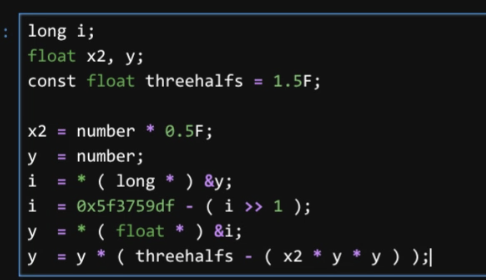

In [ ]:
# декораторы
# функции - это простой объект в питоне, и с ней чисто технически можно делать тоже самое что и с числами

# это декоратор
def foo(f):
    def wrapper(a, b):
        return f(2 * a, 2 * b)

    return wrapper

bar = foo(lambda a, b: a + b)
bar(1, 2)

6

Напишем декоратор, который проверяет тип аргументов перед вызовом функции

Он гарантиирует, что все позиционные аргументы, переданные в тип, имеют определеннй тип

`Callable[[аргументы], возвращаемое значение]`

`...` - любой тип

In [ ]:
from collections.abc import Callable

# параметр f - функция принимает 1 аргумент int, второй аргумент может быть какой угодно, возвращает инт
def checktype(f: Callable[[int, ...], int], t: type):
    def wrapper(*values):
        for i in values:
            assert isinstance(i, t), f'Values must be {t}, got {type(i)}'
        return f(*values)

    return wrapper

bar = checktype(lambda a, b: a + b, int)
bar(1, 2)

3

In [158]:
bar = checktype(lambda a, b: a + b + 'c', int)
bar(1, 2)

TypeError: unsupported operand type(s) for +: 'int' and 'str'

### Распаковка для последовательности

In [160]:
def foo(a, b):
    return a + b

foo(*[1, 2])

3

In [166]:
print(*[1, 2])

1 2


In [168]:
print(*{'1' : 2, '2' : 3})

1 2


### Распаковка для словаря

Нужна для распаковки словаря в пары (ключ=значение)

Используется для передаачи в функции именованных аргументов

In [163]:
def foo(a, b):
    return a + b

foo(**{'b' : 2, 'a' : 3})
foo(*[3], **{'b': 2})

5

Более наглядный пример, где распаковка словаря используется вместо передачи значений вручную

In [169]:
def setup_profile(name, age, city):
    print(f"{name}, {age}, {city}")

user_data = {
    'name' : 'ksenia',
    'age' : 22,
    'city' : 'VDK'
}

setup_profile(**user_data)

ksenia, 22, VDK


Как сделать декоратор с параметрами?? - обернуть в фукнкцию с праметрами которая возвращает декоратор

In [174]:
from collections.abc import Callable

def checktype(t: type):
    def decorator(f: Callable):
        def wrapper(*values):
            for val in values:
                assert isinstance(val, t), f'Value must be {t}, got {type(val)}'

            return f(*values)
        return wrapper
    return decorator

In [182]:
@checktype(str)
def bar(a: str, b: str):
    '''Concatenate strings 'a' and 'b'''

    return a + b

# просто вызовем
bar('2', '4')

'24'

In [185]:
# а вот два инта не пройдут компиляцию
bar(2, 4)

AssertionError: Value must be <class 'str'>, got <class 'int'>

In [ ]:
checktype(int)
# docsrting пропал из за декоратора - потому что фукнция bar на самом деле функция wrapper и у нее нет докстринг, его не будет

Питон - это язык программирования без магии, то есть все, что доступно в питоне, можно на том же самом питоне и написать

 wrapper.__doc__ = f.__doc__

 У функции можно достать все параметры которые она принимает и декоратор фрапперс тоже есть!!!

In [186]:
from functools import wraps

from collections.abc import Callable

def checktype(t: type):
    def decorator(f: Callable):
        @wraps(*values)
        def wrapper(*values):
            for val in values:
                assert isinstance(val, t), f'Value must be {t}, got {type(val)}'

            return f(*values)
        return wrapper
    return decorator

## List comprehention - быстрый способ создания списка

Поговрит про list comprehention - это способ создать список быстро

In [188]:
a = [i for i in range(10)]

In [189]:
a

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

In [190]:
a = [i * j for i in range(10) for j in range(2)]

In [191]:
a

[0, 0, 0, 1, 0, 2, 0, 3, 0, 4, 0, 5, 0, 6, 0, 7, 0, 8, 0, 9]

Ограничения такие же как и в лямбда-функциях действуют

In [102]:
a = input().strip().split()

values = []

for i in a:
    values.append(int(i))

values

[1, 2, 3]

#### Способ считать числа из консоли

In [192]:
values = [int(i) for i in input().strip().split()]
# предпочтиельнее чем нижний

In [193]:
values

[1]

еще один способ

In [104]:
values = list(map(int, input().strip().split()))
values

[1, 2, 3]

### List comprehention для коллекции

In [105]:
{ i: j for i, j in zip(range(10), range(9, -1, -1))}

{0: 9, 1: 8, 2: 7, 3: 6, 4: 5, 5: 4, 6: 3, 7: 2, 8: 1, 9: 0}

В питоне нет интерпретации в jump поэтому код фукнции вставляется прям там где он вызывается, а не перескакивает в памяти, из-за этого код чуть медленнее работает, но в срденем никакого замедления нет так как язык сам по себе медленный

Почти все компилируемые языки ставит джампы (возможно наоборот)

Практика

In [118]:
cats = {
    'C': 'A',
    'A': 'T',
    'T': 'S'
}

word = 'CATS'
next_letter = { i: j for i in word[:-1] for j in word[1:]}
next_letter

# напишем цикл явно

next_letter = {}

for i in word[:-1]:
    for j in word[1:]:
        next_letter[i] = j

next_letter

next_letter = {word[i - 1]: word[i] for i in range(1, len(word))}
next_letter

next_letter = {}
# можно зип
next_letter = {i : j for i, j in zip(word[:-1], word[i:])}

TypeError: slice indices must be integers or None or have an __index__ method

In [ ]:
n = int(input())
m = int(input())

mx_count = []

for i in range(n):
    a = []
    for j in range(m):
        a.append(mx[i][j] == 'C')
    mx_count.append(a)

cats = 'CATS'
for k in range(1, 4):
    temp = []
    for i in range(n):
        temp.append([0] * m)
        for j in range(m):
            if mx[i][j] != cats[k]:
                continue
            for ii in (-1, 0, 1):
                for jj in (-1, 0, 1):
                    new_i = i + ii
                    new_j = j + jj

                    if 0 <= new_i < n and 0 <= new_j < m and mx[new_i][new_j] == cats[k - 1]:
                        temp[i][j] += mx_count[new_i][new_j]
    mx_count = temp

ans = 0
for i in mx_count:
    ans += sum(i)
    
print(ans)

NameError: name 'mx' is not defined

In [123]:
# почитаем фибоначи - текущее = сумма предыдущих 

def fibbonacci(n: int) -> int:
    # можно match добавить типа свитч кейс

    match n:
        case 0:
            return 0
        case 1:
            return 1
        case _:
            return fibbonacci(n - 2) + fibbonacci(n - 1)

    # if n == 0:
    #     return 0
    # if n == 1:
    #     return 1
    
    # return fibbonacci(n - 2) + fibbonacci(n - 1)

fibbonacci(4)

3

In [127]:
# почитаем фибоначи - текущее = сумма предыдущих 

def fibbonacci(n: int) -> int:
    # можно match добавить типа свитч кейс

    a, b = 0, 1
    for i in range(n):
        a, b = b, a + b

    return a

fibbonacci(5)

5

In [ ]:
# одномерная динамика

# почитаем фибоначи - текущее = сумма предыдущих 

def fibbonacci(n: int) -> int:
    # можно match добавить типа свитч кейс

    values = 

    match n:
        case 0:
            return 0
        case 1:
            return 1
        case _:
            return fibbonacci(n - 2) + fibbonacci(n - 1)

    # if n == 0:
    #     return 0
    # if n == 1:
    #     return 1
    
    # return fibbonacci(n - 2) + fibbonacci(n - 1)

fibbonacci(4)

# надо пинаписать декоратор, который помнит какие значения уже почитаны

In [ ]:
from typing import Callable

def cache(f: Callable[[int], int]):
    memory = {} 

    def wrapper(n: int) -> int:
        
        if n not in memory:
            memory[n] = f(n)
        
        return memory[n]

    return wrapper

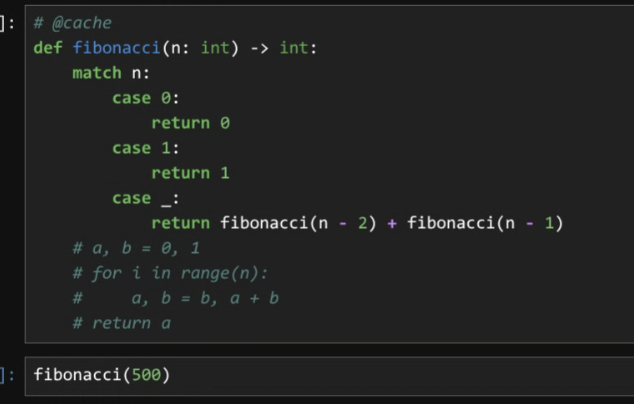

Декоратор вычисления времени работы

In [ ]:
import time

def execition_time(f):
    @function.wraps(f)

    def wrapper(*args, **kwargs):
        start = time.time()

        f(*args, **kwargs)
        end = time.time()

        print(f'{f.__name}Exectution time {end - start}')

    return wrapper



In [132]:
time.time()

1790398422.2732038

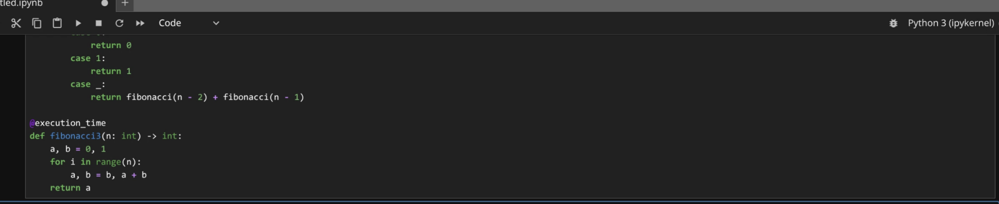

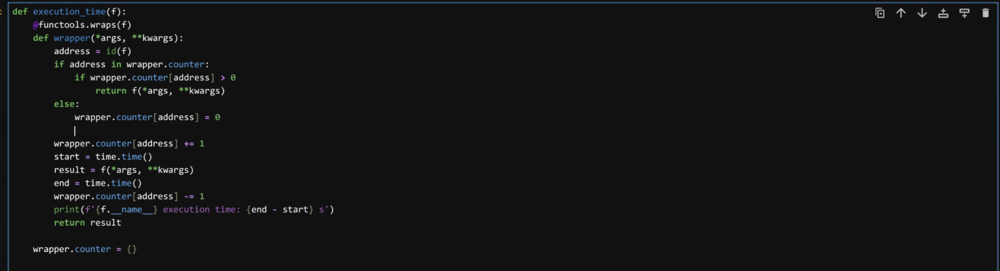

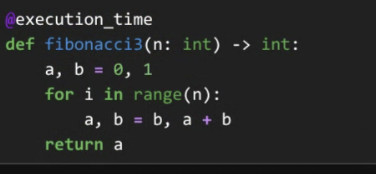

Функция декоратор которая добавляет элемнет параметр по умолчанию

In [ ]:
from typing import Any
import inspect

def add_defaults(default: Any) -> Callable[[Callable], Callable]:
    def decorator(func: Callable) -> Callable:
        def wrapper(*args: Any) -> Any:


            

In [ ]:
@add_defaults(3)
@add_defaults(3)

def foo(a: int, b: int, c: int = 4) -> int:
    return a + b + c

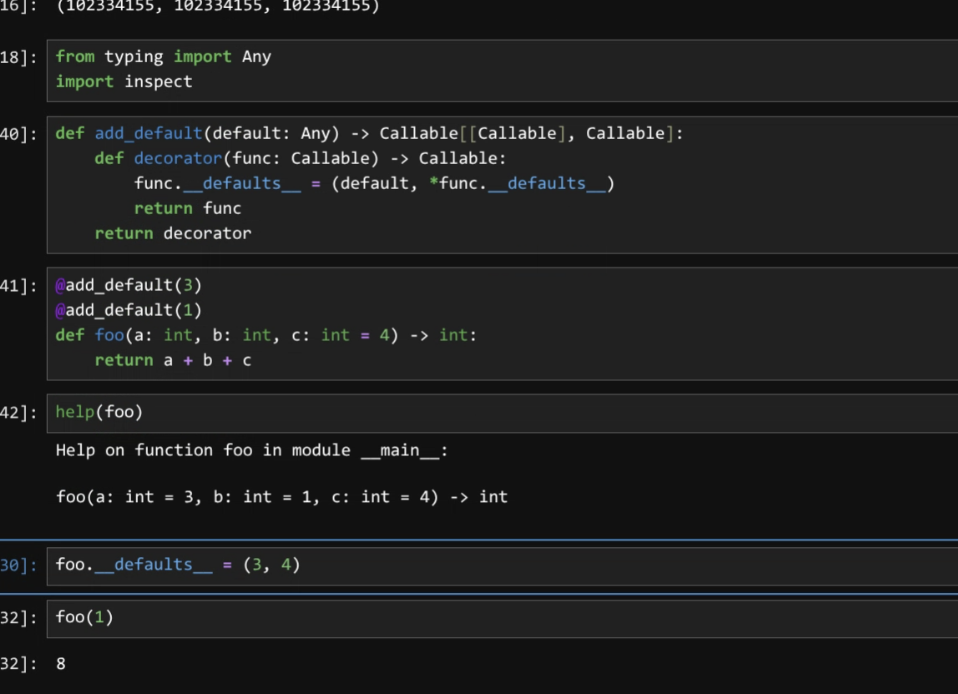

Но если у кода нет дефолтных параметров то это функция сломается

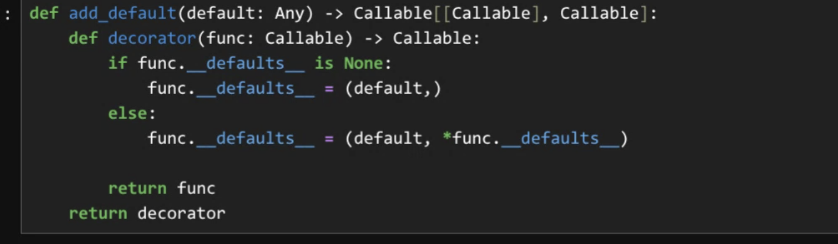

Еще короче
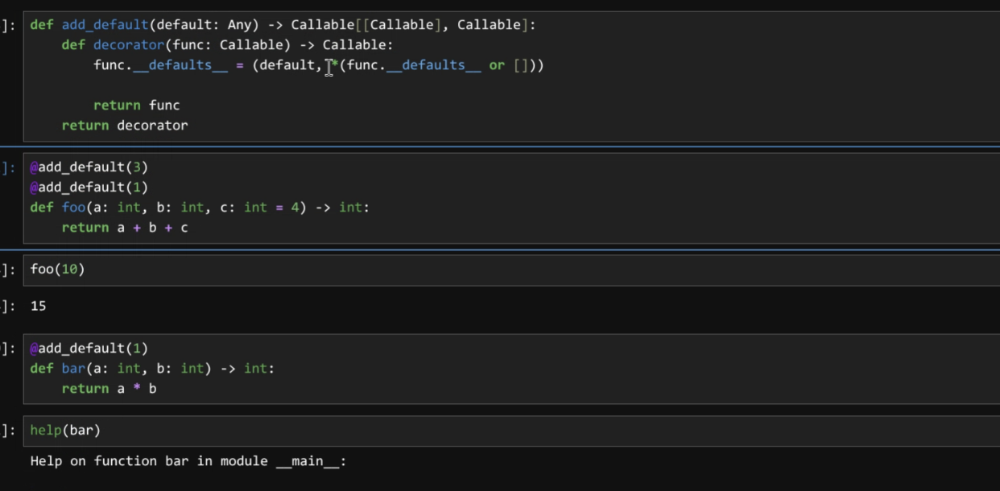

Пусть есть функция с параметрами

Если функция вызывается так что какой то параметр по умолчанию, то он по умолчанию, если список - то список используется

Копия 

In [ ]:
def append_to_list(a: int, to: list[int] = []) -> list[int]:
    to.append(a)
    return a

append_to_list(10)
append_to_list(10, [])

def helpListhard(func: Callable) -> Callable:
    def wrapper(*args):
        


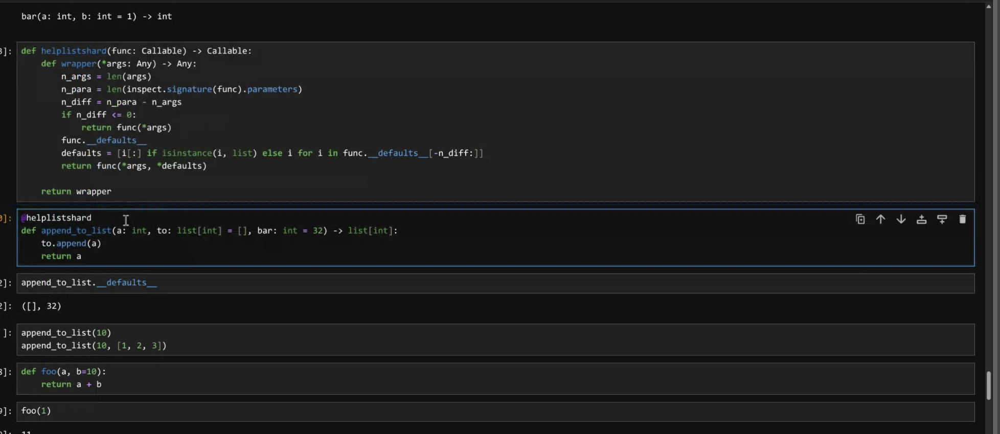

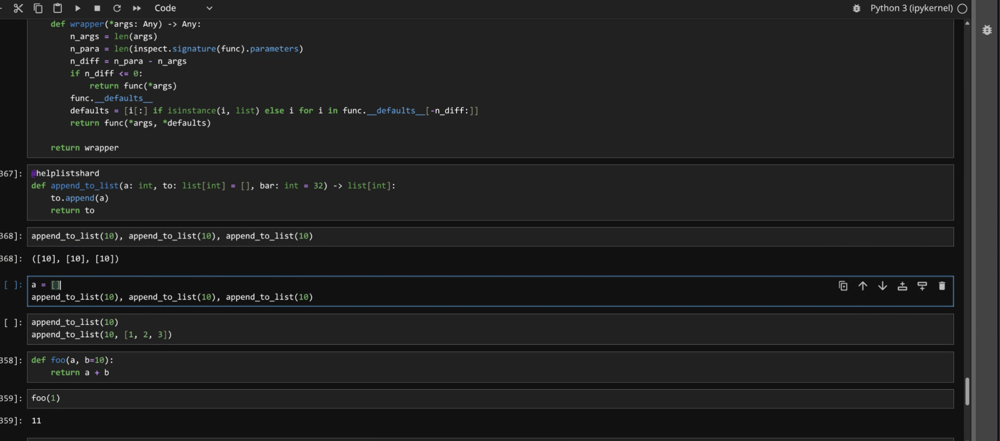

Враппер
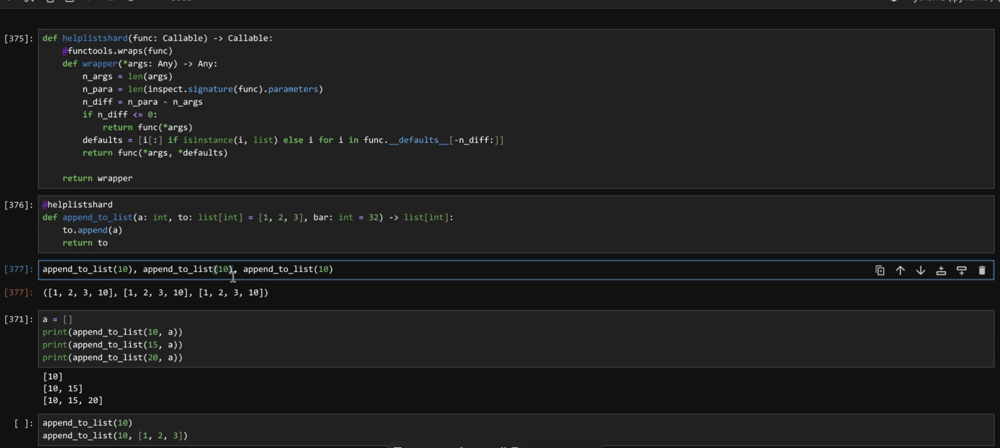

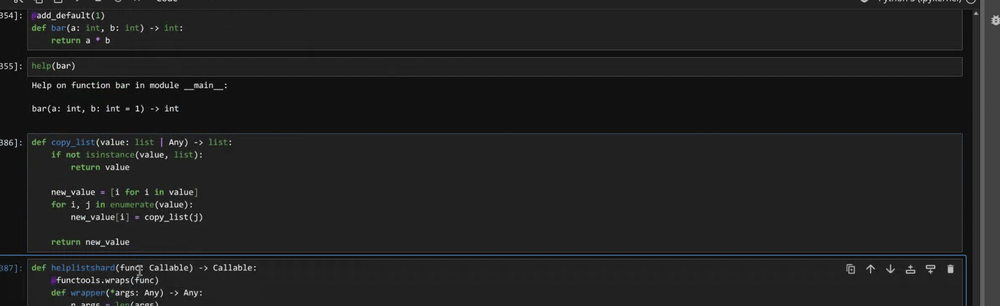

или вот так
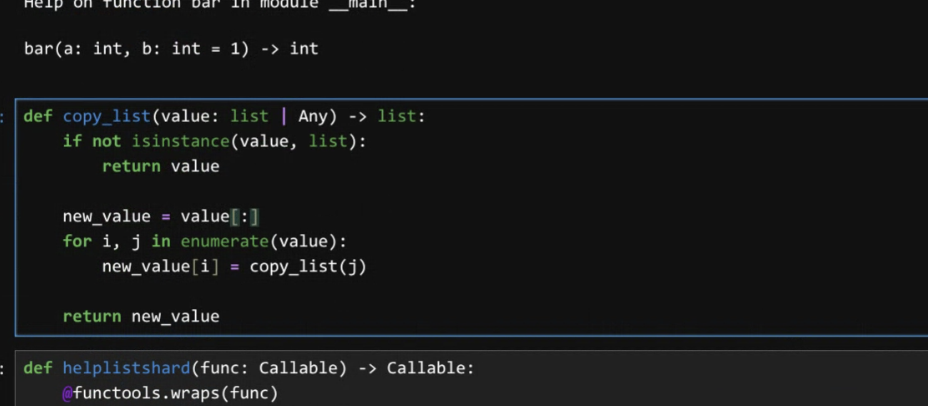

И послденее улучшение

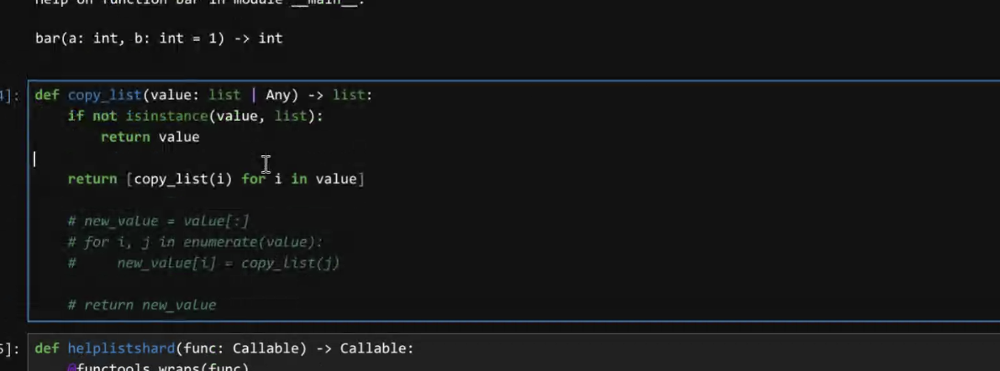

Ну и вот такое улушчение еще можно чтобы было менбще проваерок
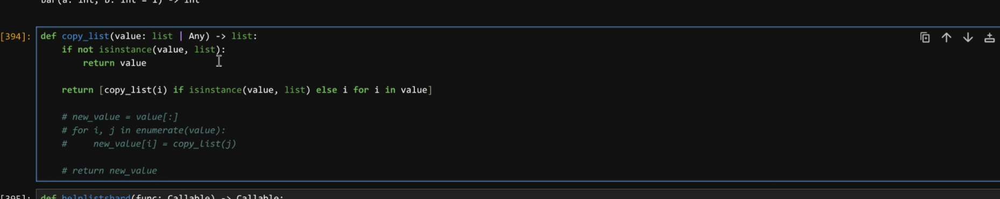

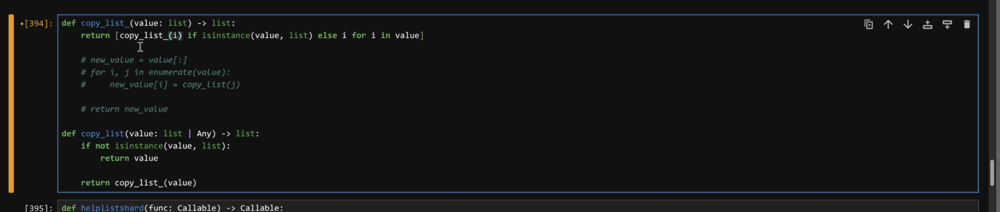

### Практика 2

In [ ]:
def Add(x, y):
    return x + y

In [31]:
def PrintMatrix(matrix: list[list[int]]):
    for el in matrix:
        print(*el)

PrintMatrix([[1, 2, 3], [4, 5, 6]])

1 2 3
4 5 6


In [43]:
from typing import Callable

def Map(func: Callable, l: list):
    for i in range(len(l)):
        l[i] = func(l[i])

    return l

print(sum(Map(lambda x: x**2, [2, 3])))


13


In [ ]:
def Join(array, separator = ' '):
    resstr = ''
    for i in range(len(array)):
        resstr += array[i]

        if i == len(array) - 1:
            break

        resstr += separator

    return resstr
    
ary = ['aa', 'bb', 'cc']
print(Join(ary, '!'))




aa!bb!cc


Что тут надо помнить

Оператор AND - возвраащет первое false значение в цепочке, если все истина, то последнее

Оператор OR - возвращает первое true значение в цепочке, если все ложно то последнее

In [ ]:
def processingForDict(data: dict, key: str, kind : str | None = None):
    return (key in data and (kind is None or data.get("kind") == kind)) and data[key]


def processing(data: dict, kind: str | None = None, counter = None):
    counter = counter or 0

    is_str = type(data) is str
    is_dict = type(data) is dict
    is_list = type(data) is list

    key = (is_dict and next(iter(data))) or None

    current_kind = (kind or (is_dict and 'kind' in data and data['kind']) or key) or None

    print('Данные', data)
    print('Ключ из объекта', key)
    print('итоговый ключ', current_kind)
    print('-----')

    return (
        (
         (is_dict and processingForDict(data, "name", kind)) and processing(data['name'], current_kind) or
         (is_dict and processingForDict(data, "names", kind)) and processing(data['names'], current_kind) or
         (is_str and [data]) or []) 
        + 
        (is_list and counter < len(data) and (
            processing(data[counter], current_kind, 0) +
            processing(data, kind, counter + 1)
        ) or (
            is_dict and (key is not False) and processing(data[key], current_kind)
        ) or (
            is_dict and (key is False) and processing(data.values(), current_kind)
        ) or [])
    )

    # ) or (
    #     is_str and "name" in data and processingForStr(data["name"])
    # )

    
    
    # or (type(data[key]) is dict and key == "name" and (routergForDict(data, kind), True)) or (type(data[key]) is list and key == "name" and (routergForDict(data, kind), True)) or (type(data[key]) is list and key != "name" and (processingForCollection(data[key], kind), True))


def get_all_names(data: str | dict | list, kind: str | None = None) -> list[str]:


    
    """Collect all names from the `data` object. If `kind` is not None, only collects names of that kind.

    Arguments:
        data: object to collect names from

    Returns:
        Collected names
    """

    
    return (type(data) is str and processingForStr(data, kind)) or (type(data) is dict and routergForDict(data, kind)[0])

data2 = {
    'human': [
{
                'name': 'lyonya',
                'kind': 'animal'
            },
            {
                'name': 'vasya',
            },
            
        ]
} 

data3 = {
    'animal': [
{
                'name': 'ksenia',
                'kind': 'human'
            },
            {
                'name': 'lion',
            },
            
        ]
} 

data1 =  {
    'name': 'petya',
    'kind': 'human'
}

	

data = [
    'petya',
    {
        'names': ['barsik', 'mursik'],
        'kind': 'animal',
        'garbage': 123
    },
    {
        'human': [
            {
                'name': 'vasya',
            },
            {
                'name': 'lyonya',
                'kind': 'animal'
            }
        ]
    }
]


# print(get_all_names('fdsf'))

print((processing([data])))

petya barsik mursik ;
petya ;
petya barsik mursik ;


Если ключ false - то текущий объект это список []

Если ключ True - то текущий объект это объект {}, строка

data2 = {
    'human': [
        {
        'human': [
                {
                    'name': 'vasya',
                },
                'human': [
                    {
                    'human': [
                            {
                                'name': 'vasya',
                            },
                            {
                                'name': 'lyonya',
                                'kind': 'animal'
                            }
                        ]
                },
            ]
    },

            {
            'name': 'lyonya',
            'kind': 'animal'
            }
    ]
} 

1 рекурсия:

Если мы видм ключ, то заходим внутрь объекта рекурсивно

def f(data: dict):
    key = key(iter(data)) or false

    return (key and f(data[key]))

    

In [ ]:
def get_all_names(data: str | dict | list, kind: str | None = None) -> list[str]:
    """Collect all names from the `data` object. If `kind` is not None, only collects names of that kind.

    Arguments:
        data: object to collect names from

    Returns:
        Collected names
    """
    accum = []

    _process(data, accum, kind)

    return accum


def _process(data, accum: list[str], kind: str | None = None, counter: int = 0):
    is_str = type(data) is str
    is_dict = type(data) is dict
    is_list = type(data) is list

    new_kind = (is_dict and data.get('kind')) or kind

    is_str and (kind is None or kind == new_kind) and accum.append(data)

    is_list and counter < len(data) and (
        (_process(data[counter], accum, kind)) or
        _process(data, accum, kind, counter + 1)
    )

    is_dict and 'name' in data and (
        _process(data['name'], accum, new_kind)
    )

    is_dict and 'names' in data and (
        _process(data['names'], accum, new_kind)
    )

    is_dict and 'name' not in data and 'names' not in data and (
        _process(list(data.values()), accum, new_kind)
    )
	
data = [
    123,
    {
        'names': ['barsik', 'mursik'],
        'kind': 'animal',
    },
    {
        'names': ['petya', 'vasya', 123],
        'kind': 'human',
    }
]

print(((get_all_names(data, 'human'))))

['barsik', 'mursik', 'petya', 'vasya']


In [255]:
def get_all_names(data: str | dict | list, kind: str | None = None) -> list[str]:
    """Collect all names from the `data` object. If `kind` is not None, only collects names of that kind.

    Arguments:
        data: object to collect names from

    Returns:
        Collected names
    """
    accum = []

    _process(data, accum, kind)

    return accum


def _process(data, accum: list[str], kind: str | None = None, counter: int = 0, is_inner: bool = False):
    is_str = type(data) is str
    is_dict = type(data) is dict
    is_list = type(data) is list

    is_str and accum.append(data)

    # current_kind = (
    # (is_dict and data.get('kind')) or
    # (is_dict and 'name' not in data and 'names' not in data and list(data.keys())[0]) or
    # None
    # )

    current_kind = (is_dict and data.get('kind')) or None

    is_valid = (current_kind is kind) or (kind is None)
    is_inner_valid = is_inner and ((current_kind is kind) or current_kind is None)

    # print('curretn', current_kind)
    # print('parent', kind)
    # print('data', data)
    # print('is_valid', is_valid)
    # print('is_inner_valid', is_inner_valid)
    # print('counter', counter)
    # print('is_inner', is_inner)

    # print('\n')

    not is_inner and (is_dict and 'name' in data and is_valid and (_process(data['name'], accum, kind)) 
                   or is_dict and 'names' in data
    and is_valid and (
                        _process(data['names'], accum, kind))
    or is_list and counter < len(data) and (
                        (_process(data[counter], accum, kind)) or
                        _process(data, accum, kind, counter + 1))
    or (
        (is_dict and kind in data ) and _process(data[kind], accum, kind, counter=0, is_inner=True)
    )) or is_inner and (is_dict and 'name' in data and is_inner_valid and  (
                            _process(data['name'], accum, kind, is_inner=True)
        ) or is_dict and 'names' in data and is_inner_valid and (
                            _process(data['names'], accum, kind, is_inner=True))
        or is_list and counter < len(data) and (
                            (_process(data[counter], accum, kind, is_inner=True)) or
                            _process(data, accum, kind, counter + 1, is_inner=True)
        )
        or (
            (is_dict and kind in data) and _process(data[kind], accum, kind, is_inner=True)
        ))

data = [
    123,
    {
        'names': ['barsik', 'mursik'],
        'kind': 'animal',
    },
    {
        'names': ['petya', 'vasya', 123],
        'kind': 'human',
    }
]

print(*get_all_names(data), ';')
print(*get_all_names(data, 'human'), ';')
print(*get_all_names(data, 'animal'), ';')


barsik mursik petya vasya ;
petya vasya ;
barsik mursik ;


In [267]:
def is_str(value):
    return type(value) is int

all(map(lambda x: is_str(x), [1, 2, '4']))

False

In [266]:
(all(map(lambda x: is_str(x), [1, 2, '4'])))

False

In [269]:
import builtins


def get_all_names(data: str | dict | list, kind: str | None = None) -> list[str]:
    """Collect all names from the `data` object. If `kind` is not None, only collects names of that kind.

    Arguments:
        data: object to collect names from

    Returns:
        Collected names
    """
    accum = []

    _process(data, accum, kind)

    return accum

def is_str(value):
    return type(value) is str

def _process(data, accum: list[str], kind: str | None = None, counter: int = 0, is_inner: bool = False):
    is_str = type(data) is str
    is_dict = type(data) is dict
    is_list = type(data) is list

    is_str and accum.append(data)

    # current_kind = (
    # (is_dict and data.get('kind')) or
    # (is_dict and 'name' not in data and 'names' not in data and list(data.keys())[0]) or
    # None
    # )

    current_kind = (is_dict and data.get('kind')) or None

    print('curretn', current_kind)
    print('parent', kind)
    print('data', data)
    print('condition', is_dict and all(map(lambda x: is_str(x), data['names'])))

    print('\n')

    is_valid = (current_kind is kind) or (kind is None)
    is_inner_valid = is_inner and (current_kind is kind) or current_kind is None

    not is_inner and (is_dict and 'name' in data and is_valid and (_process(data['name'], accum, kind)) 
                   or is_dict and 'names' in data and builtins.all(map(lambda x: is_str(x), data['names']))
    and is_valid and (
                        _process(data['names'], accum, kind))
    or is_list and counter < len(data) and (
                        (_process(data[counter], accum, kind)) or
                        _process(data, accum, kind, counter + 1))
    or (
        (is_dict and kind in data ) and _process(data[kind], accum, kind, is_inner=True)
    )) or is_inner and (is_dict and 'name' in data and is_inner_valid and  (
                            _process(data['name'], accum, kind)
        ) or is_dict and 'names' in data and is_inner_valid and builtins.all(map(lambda x: is_str(x), data['names'])) and (
                            _process(data['names'], accum, kind)
        or is_list and counter < len(data) and (
                            (_process(data[counter], accum, kind)) or
                            _process(data, accum, kind, counter + 1)
        ))
        or (
            (is_dict and kind in data) and _process(data[kind], accum, kind, is_inner=True)
        ))

data = [
    'petya',
    {
        'names': ['barsik', 'mursik'],
        'kind': 'animal',
        'garbage': 123
    },
    # {
    #     'human': [
    #         {
    #             'name': 'vasya',
    #         },
    #         {
    #             'name': 'lyonya',
    #             'kind': 'animal'
    #         }
    #     ]
    # }
]


# ['petya', 'barsik', 'mursik', 'vasya', 'lyonya']

print(((get_all_names(data, 'human'))))

curretn None
parent human
data ['petya', {'names': ['barsik', 'mursik'], 'kind': 'animal', 'garbage': 123}]
condition False


curretn None
parent human
data petya
condition False


curretn None
parent human
data ['petya', {'names': ['barsik', 'mursik'], 'kind': 'animal', 'garbage': 123}]
condition False


curretn animal
parent human
data {'names': ['barsik', 'mursik'], 'kind': 'animal', 'garbage': 123}


TypeError: 'bool' object is not callable

In [56]:
def processingForStr(data: str, kind : str | None = None):
    return (kind is None and data) or None


def routergForDict(data: dict, kind : str | None = None):
     return (
         ("name" in data and processingForDict(data, kind) and (processingForDict(data, kind), True)) or 
         ("names" in data and processingForDicts(data, kind) and (processingForDicts(data, kind), True))
     )

# работает
def processingForDict(data: dict, kind : str | None = None):
    return (kind is None and data['name']) or ("kind" in data and kind is data["kind"] and data['name']) or None

# работает
def processingForDicts(data: dict, kind : str | None = None):
    return (kind is None and data['names']) or ("kind" in data and kind is data["kind"] and data['names']) or None


def processing(data: dict, kind: str | None = None, counter = None):
    counter = counter or 0

    is_str = type(data) is str
    is_int = type(data) is int
    is_dict = type(data) is dict
    is_list = type(data) is list

    key = is_dict and next(iter(data)) 

    current_kind = kind or (is_dict and 'kind' in data and data['kind']) or key

    print('Данные', data)
    print('ключ из объекта', key)
    print('итоговый ключ', current_kind)
    print('-----')

    return (
       (((is_dict and 'name' in data and (kind is None or not "kind" in data or data["kind"] == kind)) and processing(data['name'], current_kind)) or 
         ((is_dict and 'names' in data and (kind is None or not "kind" in data or data["kind"] == kind)) and processing(data['names'], current_kind)) or 
         ((is_str) and [data]) or []) 
        
        + 
        (is_list and counter < len(data) and (
            processing(data[counter], current_kind, 0) +
            processing(data, kind, counter + 1)
        ) or (
            is_dict and (key is not False) and processing(data[key], current_kind)
        ) or (
            is_dict and (key is False) and processing(data.values(), current_kind)
        ) or [])
    )





    # ) or (
    #     is_str and "name" in data and processingForStr(data["name"])
    # )

    
    
    # or (type(data[key]) is dict and key == "name" and (routergForDict(data, kind), True)) or (type(data[key]) is list and key == "name" and (routergForDict(data, kind), True)) or (type(data[key]) is list and key != "name" and (processingForCollection(data[key], kind), True))


def get_all_names(data: str | dict | list, kind: str | None = None) -> list[str]:


    
    """Collect all names from the `data` object. If `kind` is not None, only collects names of that kind.

    Arguments:
        data: object to collect names from

    Returns:
        Collected names
    """

    
    return (type(data) is str and processingForStr(data, kind)) or (type(data) is dict and routergForDict(data, kind)[0])

data2 = {
    'human': [
{
                'name': 'lyonya',
                'kind': 'animal'
            },
            {
                'name': 'vasya',
            },
            
        ]
} 

data3 = {
    'animal': [
{
                'name': 'ksenia',
                'kind': 'human'
            },
            {
                'name': 'lion',
            },
            
        ]
} 

data1 =  {
    'name': 'petya',
    'kind': 'human'
}

data = [
    123,
    {
        'names': ['barsik', 'mursik'],
        'kind': 'animal',
    },
    {
        'names': ['petya', 'vasya', 123],
        'kind': 'human',
    }
]


# print(get_all_names('fdsf'))

print(set(processing(data)))

Данные [123, {'names': ['barsik', 'mursik'], 'kind': 'animal'}, {'names': ['petya', 'vasya', 123], 'kind': 'human'}]
ключ из объекта False
итоговый ключ False
-----
Данные 123
ключ из объекта False
итоговый ключ False
-----
Данные [123, {'names': ['barsik', 'mursik'], 'kind': 'animal'}, {'names': ['petya', 'vasya', 123], 'kind': 'human'}]
ключ из объекта False
итоговый ключ False
-----
Данные {'names': ['barsik', 'mursik'], 'kind': 'animal'}
ключ из объекта names
итоговый ключ animal
-----
Данные ['barsik', 'mursik']
ключ из объекта False
итоговый ключ animal
-----
Данные barsik
ключ из объекта False
итоговый ключ animal
-----
Данные ['barsik', 'mursik']
ключ из объекта False
итоговый ключ animal
-----
Данные mursik
ключ из объекта False
итоговый ключ animal
-----
Данные ['barsik', 'mursik']
ключ из объекта False
итоговый ключ animal
-----
Данные [123, {'names': ['barsik', 'mursik'], 'kind': 'animal'}, {'names': ['petya', 'vasya', 123], 'kind': 'human'}]
ключ из объекта False
итоговый 

In [ ]:
def processingForDict(data: dict, key: str, kind : str | None = None):
    return (key in data and (kind is None or data.get("kind") == kind)) and data[key]


def processing(data: dict, kind: str | None = None, counter = None):
    counter = counter or 0

    is_str = type(data) is str
    is_dict = type(data) is dict
    is_list = type(data) is list

    key = (is_dict and next(iter(data))) or None

    current_kind = (is_dict and key not in ('name', 'names') and key) or kind or (is_dict and 'kind' in data and data['kind']) or None

    return (
        (
         (is_dict and processingForDict(data, "name", kind)) and processing(data['name'], current_kind) or
         (is_dict and processingForDict(data, "names", kind)) and processing(data['names'], current_kind) or
         (is_str and [data]) or []) 
        + 
        (is_list and counter < len(data) and (
            processing(data[counter], current_kind, 0) +
            processing(data, current_kind, counter + 1)
        ) or (
            is_dict and (key is not None) and (key not in ('name', 'names')) and processing(data[key], current_kind)
        ) or (
            is_dict and (key is None) and processing(list(data.values()), current_kind)
        ) or [])
    )


def get_all_names(data: str | dict | list, kind: str | None = None) -> list[str]:
    """Collect all names from the `data` object. If `kind` is not None, only collects names of that kind."""
    return processing(data, kind) or []


data = [
    'petya',
    {
        'names': ['barsik', 'mursik'],
        'kind': 'animal',
        'garbage': 123
    },
    {
        'human': [
            {
                'name': 'vasya',
            },
            {
                'name': 'lyonya',
                'kind': 'animal'
            }
        ]
    }
]

print(*get_all_names(data), ';')
print(*get_all_names(data, 'human'), ';')
print(*get_all_names(data, 'animal'), ';')

In [22]:
# Декораторы
from typing import Callable

def counter_decorator2(f: Callable) -> Callable:
    '''Decorates `f` to print number of calls each call.'''
    counter = 0
    counter = [counter]
    def wrapper(*args, **kargs):
        res = f(*args, **kargs)
        counter[0] += 1
        print(f'Function calls count: {counter}')
        return res

    return wrapper

from typing import Callable

from typing import Callable

def counter_decorator(f: Callable) -> Callable:
    '''Decorates `f` to print number of calls each call.'''

    def wrapper(*args, **kargs):
        wrapper.counter += 1
        print(f'Function calls count: {wrapper.counter}')

        res = f(*args, **kargs)

        return res

    wrapper.counter = 0


    return wrapper

def projection_decorator(f: Callable[[int], None]) -> Callable[[int, int, int], None]:
    '''Decorates `f` as a function of three arguments x, y, z that calls `f` with a single argument $3x-7y+15z+18$'''
    def wrapper(*args):

        res = 3 * args[0] - 7*args[1] + 15*args[2] + 18
        res = f(res)

    return wrapper


In [273]:
from typing import Callable

def counter_decorator(f: Callable) -> Callable:
    '''Decorates `f` to print number of calls each call.'''
    def wrapper(*args, **kwargs):
        wrapper.counter += 1
        print(f'Function calls count: {wrapper.counter}')
        
        res = f(*args, **kwargs)
        return res

    wrapper.counter = 0
    return wrapper

def projection_decorator(f: Callable[[int], None]) -> Callable[[int, int, int], None]:
    '''Decorates `f` as a function of three arguments x, y, z that calls `f` with a single argument $3x-7y+15z+18$'''
    def wrapper(x: int, y: int, z: int):
        res = 3 * x - 7 * y + 15 * z + 18
        return f(res)
        
    return wrapper

def sum(a: int, b: int):
    print(a + b)

fn = counter_decorator(sum)
fn(1, 2)
fn(4, 5)
fn(-4, 5)



Function calls count: 1
3
Function calls count: 2
9
Function calls count: 3
1


In [4]:

def counter_decorator(f):
    def wrapper(*args, **kwargs):
            wrapper.counter += 1
            print(f'Function calls count: {wrapper.counter}')
            
            res = f(*args, **kwargs)
            return res
    
    wrapper.counter = 0
    return wrapper

def projection_decorator(f):
    def wrapper(x, y, z):
        res = 3 * x - 7 * y + 15 * z + 18
        return f(res)
        
    return wrapper

def sum(a: int, b: int):
    print(a + b)

@projection_decorator
def calc(x: int):
    print(x * x)

calc(1, 2, 3)

2704


In [23]:
def sum(a: int, b: int):
    print(a + b)

fn = counter_decorator(sum)
fn(1, 2)
fn(4, 5)
fn(-4, 5)

Function calls count: 1
3
Function calls count: 2
9
Function calls count: 3
1


In [16]:
@projection_decorator
def calc(x: int):
    print(x * x)

calc(1, 2, 3)


2704


## Лекция 3 (Классы и генераторы)

In [ ]:
import time

In [3]:
a = 43

match a:
    case 42 if int(time.time()) % 2 == 0:
        print('a is 42')
    case 43:
        print('a is 43')
    case _:
        print('other')

a is 43


Особенности
- умеет матчить классы

In [ ]:
a = 43

match a:
    case int():
        print('a is int')
    case str():
        print('a is str')
    case _:
        print('other')

Особенности
- нельзя инстансы 
- есть какой то механизм - превратиться в паттерн и для кастомных классов надо это  (прочитать) 

In [5]:
class Dog:
    def __init__(self):
        self.name = name
match a:
    case Dog('foo'):
        print('a is int')
    case  str():
        print('a is str')
    case _:
        print('other')

other


In [ ]:
a = (43, 'str') # для tuple есть шаблоны, а для кастомных типов нет, поэтому так

match a:
    case (str(), int()):
        print('a is int')
    case (int(), str()):
        print('a is str')
    case _:
        print('other')

a is str


In [10]:

a = [1, 2, 3, 4, 5]
a = [1, 2, 3, 4, 5], (42, (), (), 10.5, '123')

match a:
    case (str(), int()):
        print('a is int')
    case (int() as first, str() as second):
        print(f'is {first} {second}')
    case [1, 2, 3, *rest]:
        print(rest)
    case [1, 2, 3, *rest, (int(), *also, str())]:
        print(rest, also)
    case _:
        print('other')

other


можно матчить словари

In [ ]:

a = [1, 2, 3, 4, 5]
a = [1, 2, 3, 4, 5], (42, (), (), 10.5, '123')
a = [1, 2, 3, 4, '5']

match a:
    case (str(), int()):
        print('a is int')
    case (int() as first, str() as second):
        print(f'is {first} {second}')
    case [1, 2, 3, *rest]:
        print(rest)
    case [1, 2, 3, *rest, (int(), *also, str())]:
        print(rest, also)
    case  {'spices' : str() as spices, 'name': str() as name, 'age' : int() as age}:
        print(f'{spices} od name \'{name}\', aged {age}')
    # проверка на то что в списке все элементы инты с созданием переменной
    case list() as values if all([isinstance(i, int) for i in values]):
        print('no')
    case _:
        print('other')

# выбирается первый кейс, даже если несколько пододящих вариантов 


other


Класс

In [25]:
# класс это способ организации кода
# ыедлить пкамять - init - потом вызывать то что получилось
class Dog:
    a = 1

    def __init__(self, name: str):
        self.name  = name        


dog = Dog('Dog 1')
dog = Dog('Dog 2')

dog.a
a = 45
dog.a = 54

# питон смотрит на переменную как global, если мы передадим через .a то тоеперь эта а будет исопльзовать как локальная 

Dog.a
dog.a

54

In [ ]:
# есть функция 
class Dog:

    # обязана возвращать ничего
    def __init__(self, name: str):
        self.name  = name    
        self.ball = None

    def bark(self):
        print('Woof')    

    def catch_ball(self, ball: str):
        if self.ball is not None:
            self.ball = None
            self.bark()
            return

        self.ball = ball

    def take_nbball(self) -> str:
        ball = self.ball
        self.ball = None

        return ball

    def __str__(self) -> str:
        return f'Dog name is {self.name}'

    def __add__(self, ball: str):
        # разобрать
        self.catch_ball(ball)
        return self

    # почиатть что такое r и что оно делает, 
    def __radd__(self, ball: str):
            # разобрать
            self.catch_ball(ball)
            return self
    # /
    def __floordiv__(self, value: int) ->list[str]:
        return [Dog(name=self.name) for i in range(value)]

    # div - //
    # true div //
    def __div__(self, value: int) ->list[str]:
        return [Dog(name=self.name) for i in range(value)]

    # никогда нельзя писать new
    def __dell__(self):
        print('dog died')

    def __len__(self):
        return len(self.name)

    def __getitem__(self, index):
        return self.name[index]

    def __dir__(self):
        pass

    # не поняла зачем это если честно надо почитать
    # чем отличается gettatr от getattribute (она первая вызывает, елси ее нет то вызывается getattr и получается она работает когда у объекта нет поля какого то которе мы )
    def __getattr__(self, name):
        return f'какой то текс {name}'

    # есть еще setattr setattribute
    # не совсем понятно когда и что прописывать и зачем это надо, 

    def __(self, name):
        print(name)
        return super().__getattribute__(name)
    
    # вернуть строку которая предсталяет инстанс (объект)
    def __repr__(self):
        return f'Dog name is {repr(self.name)}'
      


dog = Dog('Dog 1')
dog = Dog('Dog 2')

dog.bark()

Woof


In [ ]:
dog.bark
# создается bound метод
# также self это просто договорняк по имени, но на самом деле ее можно называть по разному, и его надо всегда прописывать 

<bound method Dog.bark of <__main__.Dog object at 0x10769f550>>

In [33]:
dog.take_nbball()

In [ ]:
import gc # сборщик мусора есть разные

str(dog)
# после добавления repr будет конкретная строка выводится при выводе инстанса
dog

Dog name is 'Dog 2'

In [ ]:
del dog # del вызывается только когда когда вызовится gc и полагаться на эту функцию не стоит

сборщики мусора

del - garbage collector - только циклические ссылки, ациклические он не чистит , и еще что-то 

типа есть и циклические и ациклические ссылки, то есть бывабт такие циклы между переменными, что достучаться из вне цикла нельзя до них и поэтому такие объекты тоже чистятся по расписанию, а не всегда, чтобы не нагружать интерпретатор, то есть gc смотрит если не загружено процессами, то можно вызвать тот же gc например, а не вызвать их на каждый чих


In [36]:
dog.b

NameError: name 'dog' is not defined

In [40]:
dog = Dog('new dog')
# object.__getattribute__(dog, 'values') = ['values']

In [ ]:
dog.bark = lambda self: print('нельзя гафкать')
# у собаки 

In [41]:
dog.__dict__

{'name': 'new dog', 'ball': None}

In [44]:
dog.__dir__

<function Dog.__dir__()>

In [45]:
import random

In [ ]:
class Room:

    def init(self, number: int, building: str, capacity: int):
        self.number = number
        self.building = building
        self.capacity = capacity
        self.is_occupid = False

    def str(self) -> str:
        return f'{self.building}{self.number}'

    def occupy(self):
        assert not self.is__occupied, 'ЗАНЯТО GO AWAY'

    def free(self):
        assert self.is_occupid, 'DOUBLE FREE OR CORRUPTION'

    # есть что то типа виртуальных методов, но не совсем, но проверки того, реализованы они или нет - такой проверки нет
    def look(self):
        raise NotImplementedError


In [ ]:
# super() - вывзает метод от родителя у которого он есть

class Classroom(Room):
    def __init__(self, number: int, building: str, capacity: int, enable_multimedia: bool):
        super().__init__(self, number, building, capacity, enable_multimedia)
        self.enable_multimedia = False

    def enable_multimedia(self):
        self.enable_multimedia = random.random() < 0.5

    def disble_multimedia(self):
         self.enable_multimedia = False
         
    def look(self):
        print('CANNOT LOCK')

In [63]:
classroom = Classroom(810, 'D', 42)

TypeError: Classroom.__init__() missing 1 required positional argument: 'enable_multimedia'

In [ ]:
# наследование
class Office(Room):
    def __init__(self, number: int, building: str, capacity: int, *employees: str):
        super().__init__(number, building, capacity)
        self.employees = employees

        assert len(self.employees) <= capacity

    def fire(self, employees: str):
        self.employees.remove(employees)


    def __str__(self):
        return f'{super().__str__()}({" ".join(self.employees)})'
    

изменить тип в питоне нельзя потому что типов и кастов вообще нет в питоне

In [64]:
office = Office(123, 'A', 2, 'Foo', 'Bar')

TypeError: object.__init__() takes exactly one argument (the instance to initialize)

In [ ]:
office.__dict__['lunch'] = lambda self: [self.fire(i) fro i in self.employees] # удалится вместо двух сотрудников один, потому что мы меняем исходный массив и укзаатель цикла не меняет положения
office.lunch()

In [ ]:
isinstance(office, Office) # учитвает в том числе наледоваия
type(office) is Office # тут тупо тип текщций проверяется 

можно наследоваться от базовых классов

In [66]:
class MyList(list):
    def append(self, values):
        assert values % 2 == 0
        super().append(value)

In [71]:
my_list = MyList([1, 2, 3])


In [ ]:
from dataclasses import dataclass, field
from collections import namedtuple

# можно с помощью декоратора добавить новые поля и автоматический init, который не надо будет вручную инициализировать
@dataclass
class Student:
    name: str
    age: int
    # через field это фабрика
    group: list = field(default_factory=lambda: [])

    def eat(self):
        self.age += 1
        

In [ ]:
# это решает проблему с пустыим [] при передаче аргументов (отсылка на прошлую пару)
field(default_factory=lambda: [])

Field(name=None,type=None,default=<dataclasses._MISSING_TYPE object at 0x10471c3d0>,default_factory=<function <lambda> at 0x108925750>,init=True,repr=True,hash=None,compare=True,metadata=mappingproxy({}),kw_only=<dataclasses._MISSING_TYPE object at 0x10471c3d0>,_field_type=None)

In [87]:
Student = namedtuple('Student', ['name', 'age', 'grroup'], defaults=[[]]) # нельзя написать фабрики, это старее, но код генерируется быстрее
# вот так плохо делать defaults=[[]] потому что список создается один на всю область и используется потом когда не передан параметр, надо to = None or []
student = Student('aa', 23)

In [ ]:
field()

# default=<dataclasses._MISSING_TYPE тут передано магическое щначение потому что нельзя просто None передать, так как None может быть не missing type а переданное значение, которое по другому никак не отличить

Field(name=None,type=None,default=<dataclasses._MISSING_TYPE object at 0x10471c3d0>,default_factory=<dataclasses._MISSING_TYPE object at 0x10471c3d0>,init=True,repr=True,hash=None,compare=True,metadata=mappingproxy({}),kw_only=<dataclasses._MISSING_TYPE object at 0x10471c3d0>,_field_type=None)

In [ ]:
student.group.append(23)

AttributeError: 'str' object has no attribute 'ap'

In [74]:
student = Student('Name', 1, 'Group')

In [76]:
student

Student(name='Name', age=1, group='Group')

In [75]:
student.__annotations__

{'name': str, 'age': int, 'group': str}

In [ ]:
class Student:
    def __init__(self, age: int, name: str):
        self.age = age
        self.name = name
        self.grades = None

# property - это поле которе функция
    @property
    def age(self) -> int:
        return self._age 

    @property
    def name(self) -> str:
        return self._name

    @property
    def grade(self) -> int:
        return random.radint(1, 5)
        

    @age.setter
    def age(self, value: int):
        self.age = value

    
    @grade.setter
    def grade(self, value: int):
        self._grades.append(value)

    # ну то есть это не совсем сеттер, оно просто печатает и все
    @property.setter
    def foo(self, value):
        print(value)
    # в питоне нет инкапсуляции вообще
    # @set_

    # property в питоне часто пользуются  python descriptors естьв документации и там об этом сказано

TypeError: descriptor 'setter' for 'property' objects doesn't apply to a 'function' object

In [ ]:
student = Student(23, 'name')

TypeError: Student.__init__() missing 1 required positional argument: 'name'

Генераторы

In [ ]:
a = (i for i in range(10) if a % 2 == 0)
# от list comprehention отличается тем что выполняется только в момент вызова в отлииче от list comprehention

next(a)

TypeError: unsupported operand type(s) for %: 'generator' and 'int'

In [ ]:
sum([1, 2, 3, 4 ,5 ])

sum([i for i in range(5)])

# можно не пистаь тсорые скобочки в генераторах, особенно если один аргумент это генератор, в другом не работает
sum((i for i in range(5)))

# запрашивается следующий элемент


10

- итерируемый объект (метод iter), итератор(метод iter, метод next), генератор(метод iter, метод next, метод set)

In [104]:
a = [1, 2 ,3, 4]
for i in a:
    print(i)

1
2
3
4


In [ ]:
it = iter(a)

try:
    while True:
        i = next(it)
        
        # body
        print(i)
except StopIteration:
    pass

1
2
3
4


In [107]:
class CoinFlip:

    SIDE = ['head', 'tails']
    def __init__(self, side: str):
        self.side = side

    def __iter__(self):
        return self

    def __next__(self):
        side = CoinFlip.SIDE[random.randint(0, 1)]

        if side == self.side:
            raise StopIteration

        return side

for i in CoinFlip('heads'):
    print(i)

tails
tails
head
tails
head
head
tails
tails
head
tails
head
head
tails
tails
tails
tails
head
tails
head
tails
tails
tails
tails
tails
tails
tails
tails
tails
head
tails
tails
head
tails
head
tails
head
tails
head
head
tails
head
head
tails
head
head
tails
head
tails
tails
tails
head
head
tails
tails
head
tails
tails
tails
head
tails
head
head
head
head
head
head
tails
head
head
tails
head
head
head
head
tails
tails
head
head
tails
tails
head
tails
head
tails
head
tails
head
tails
head
tails
head
head
head
head
tails
head
tails
head
tails
head
head
tails
head
head
head
head
head
tails
head
tails
tails
head
head
tails
tails
tails
tails
tails
tails
head
tails
head
head
head
tails
tails
tails
tails
head
tails
tails
head
tails
tails
tails
head
tails
head
head
tails
head
tails
head
head
tails
head
head
tails
head
head
head
head
tails
tails
head
tails
tails
head
head
tails
tails
head
tails
head
head
tails
head
tails
tails
head
head
tails
tails
head
head
tails
head
tails
tails
head
head
head

KeyboardInterrupt: 

In [108]:
coin = CoinFlip('heads')

In [ ]:
for i in coin:
    print(i)

In [ ]:
class MyListIterable:

    class MyListIterable:
        def __init__(self, values):
            self.index = 0

        def __next__(self):
            if self.index >= len(self.values):
                raise StopIteration

            value = self.values[self.index]
            return value

        def __iter__(self):
            pass

    def __init__(self, values):
        self.values = values

    def __iter__(self):
        return MyListIterable.MyListIterable(self.values)

In [ ]:
iter?

# callable то что надо возвращать в след момент итерации (ниже реализовано)

Docstring:
iter(iterable) -> iterator
iter(callable, sentinel) -> iterator

Get an iterator from an object.  In the first form, the argument must
supply its own iterator, or be a sequence.
In the second form, the callable is called until it returns the sentinel.
Type:      builtin_function_or_method

In [110]:
for i in iter(lambda: random.randint(0, 1), 1):
    print(i)

0


In [113]:
# генератор - на это указывает yield

def numbers():
    while True:
        yield a
        a += 1

a = numbers()
a

<generator object numbers at 0x108fd8430>

In [114]:
def increment():
    a = 0
    increase = 1
    while True:
        d = yield a
        if d is not None:
            increase = d

        a += increase


In [ ]:
a = increment()

0

In [119]:
next(a)

2

In [ ]:
# можно контролировать что генератор что то делает вот таким образом, но так обычно никто не делает
a.send(-1)

0

Практика

In [156]:
# декоратор функции класса для абстрактных методов которые не реализованы
# декоратор который проверяет что все методы реализованы

# getattr(method, ) - пытается получить метод поля с такми классом
from collections.abc import Callable

def get_not_implemented_methods(cls):
    # собарть все множества чтобы найти методы которые мы еще не реализовали

    not_implemented = set()

    for base in cls.__bases__:
        not_implemented |= get_not_implemented_methods(base)

    callable_methods = {
            name 
            for (name, method) in cls.__dict__.items() 
            if isinstance(name, Callable) and not getattr(method, "__not_implemented_to", False)
        }

    not_implemented -= callable_methods

    # надо добавить наши имплементированные методы
    not_implemented |= {
        name 
        for (name, method) in cls.__dict__.items() 
        if getattr(method, "__not_implemented_to", False)

    }

    return not_implemented

def not_implemented_methods(cls):
    yield from (name for (name, method) in cls.__dict__.items() if getattr(method, "__not_implemented_to", False))

    for base in cls.__bases__:
        # все неиплементированные методы родителя
        yield from not_implemented_methods(base)

def get_callable_methods(cls):
    yield from (name for (name, method) in cls.__dict__.items() if not getattr(method, "__not_implemented_to", False))

    for base in cls.__bases__:
        # все неиплементированные методы родителя
        yield from get_not_implemented_methods(base)


def not_implemented(f: Callable):
    f.__not_implemented_to = True

    return f

def check_implemented(cls: type):
    
    assert not get_not_implemented_methods(cls)

    pass

In [126]:
isinstance(Office.__dict__['fire'], Callable)

True

In [122]:
Office.__dict__

mappingproxy({'__module__': '__main__',
              '__init__': <function __main__.Office.__init__(self, number: int, building: str, capacity: int, *employees: str)>,
              'fire': <function __main__.Office.fire(self, employees: str)>,
              '__doc__': None})

In [ ]:
Office.__bases__ # выводит родительский самый верхний класс

(__main__.Room,)

In [154]:
class Foo:
    def __init__(self):
        pass
    @not_implemented
    def foo():
        pass

class Fizz():
    def foo():
        pass

class Bar(Foo):
    def __init__(self):
        pass
     
    @not_implemented
    def bar(self):
        pass

list(not_implemented_methods(Bar))

['bar', 'foo']

In [139]:
{i for i in range(10)}

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

In [140]:
{i : i + 1 for i in range(10)}

{0: 1, 1: 2, 2: 3, 3: 4, 4: 5, 5: 6, 6: 7, 7: 8, 8: 9, 9: 10}

In [149]:
@check_implemented
class FooBarr(Bar):
    pass

set()


AssertionError: Method bar is not implemented

In [153]:
@check_implemented
class FooBarr(Bar, Fizz):
    def foo(self):
        pass

set()


AssertionError: Method bar is not implemented

In [151]:
@check_implemented
class FooBarr(Bar):
    def foo(self):
        pass
    def bar(self):
        pass

set()


AssertionError: Method bar is not implemented